# ¿Con qué probabilidad una muestra de leche cruda supera el umbral de células somáticas o de bacterias? Regresión logística
**Aprendizaje Automático y Grandes Datos · UNRaf · 2026**

Modelos del apartado de regresión logística (`LogisticRegression` de scikit-learn) sobre la **leche cruda** de 10 industrias
(`IND-nn`), 2019-2026. Para cada muestra de tambo se estima la **probabilidad** de que:

* **RCS**: el recuento de células somáticas supere **400 000 cél/mL** (indicador de mastitis);
* **RBT**: el recuento bacteriano total supere **100 000 UFC/mL** (leche de primera calidad: por debajo).

**Pregunta de fondo.** El calor, ¿sube el riesgo? Estación y temperatura están confundidas (el verano es caluroso *y* es
estación), así que no alcanza con la temperatura: se usa la **anomalía** (cuánto más caliente que lo habitual para esa época del
año) con la estación en el modelo. Una probabilidad bien **calibrada** es el entregable útil, por eso se mira la curva de
calibración además del AUC.

**Cuidados que ordenan el cuaderno.** (1) **Unidades**: se confirman antes de poner umbrales (y aparece un cambio de unidad
del RBT en una industria). (2) **Validación temporal**: se entrena hasta fin de 2023 y se prueba en 2024-2026; nunca un KFold
aleatorio (las muestras de un mismo día, tambo e informe se parecen). Además, **una industria afuera** (`GroupKFold` por cliente).
(3) **Intervalos con bootstrap por bloques de semanas**: las filas no son independientes. (4) Ningún predictor deriva del objetivo.

Semilla 42. Escribe solo en `resultados/logistica_calidad_leche/`.

## 0 · Rutas y parámetros

In [1]:
import sys
import time
import warnings
from pathlib import Path
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "rutas.py").exists()) / "src"
sys.path.insert(0, str(SRC))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
from IPython.display import Markdown, display
from sklearn.metrics import roc_curve
from sklearn.model_selection import GroupKFold
import rutas as R
import logistica_leche as L

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 120)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 10.5, "axes.labelsize": 9.5,
                     "legend.fontsize": 8.5, "axes.grid": True, "grid.alpha": 0.25})
SALIDA = R.RESULTADOS / "logistica_calidad_leche"; SALIDA.mkdir(parents=True, exist_ok=True)
DICCIONARIO = R.RAIZ.parent / "_archivo" / "datos" / "diccionario_leche_cruda.csv"
DPI = 150
AZUL, NARANJA, GRIS, OSCURO = "#2a6f97", "#d9822b", "#8a8f98", "#1d3557"
COLOR = {"RCS": AZUL, "RBT": NARANJA}
NOMBRE = {"RCS": "células somáticas > 400 000 cél/mL", "RBT": "recuento bacteriano > 100 000 UFC/mL"}
T0 = time.time()
RES = {}      # resultados que alimentan las conclusiones


def en_simple(txt):
    display(Markdown("**En simple:** " + txt))


def guardar(fig, nombre):
    fig.savefig(SALIDA / nombre, dpi=DPI, bbox_inches="tight")
    plt.show()


def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n
    den = 1 + z ** 2 / n
    cen = (p + z ** 2 / (2 * n)) / den
    mar = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return cen - mar, cen + mar


print("rutas listas · semilla", L.SEMILLA)

rutas listas · semilla 42


## 1 · Carga y unidades (antes de fijar ningún umbral)
El diccionario de columnas (`_archivo/datos/diccionario_leche_cruda.csv`) da las unidades de los dos recuentos: **ambos en
miles por mL**. Se confirman con los datos, y se busca si hay valores en otra unidad o topes de medición. `archivo` no se lee.

In [2]:
dic = pd.read_csv(DICCIONARIO, encoding="utf-8-sig")
print(dic.loc[dic["variable"].isin(["celulas_somaticas", "rbt"]), ["variable", "descripcion", "unidad", "mediana", "p95", "referencia"]].to_string(index=False))
d, info = L.cargar_leche()
d, LIM = L.acotar_composicion(d)
temp, n_vacios = L.cargar_temperatura()
print()
print(info)
print("Límites de recorte de la composición (percentiles 0,1-99,9 del entrenamiento):", {k: tuple(round(x, 2) for x in v) for k, v in LIM.items()})
print("Temperatura:", temp.index.min().date(), "→", temp.index.max().date(), "· días sin dato interpolados:", n_vacios)
print("Leche cruda:", d["fecha"].min().date(), "→", d["fecha"].max().date(), "·", len(d), "filas ·", d["cliente"].nunique(), "industrias")

         variable                                          descripcion       unidad  mediana   p95                                       referencia
celulas_somaticas Recuento de células somáticas; indicador de mastitis     miles/mL    427.0 938.0 umbral de mastitis subclínica en torno a 200-400
              rbt          Recuento bacteriano total (UFC en los .txt) miles UFC/mL     48.0 993.0       leche de primera calidad por debajo de 100



{'filas_archivo': 628035, 'filas_desde_2019': 628002, 'rbt_en_ufc_descartados': 21093, 'rbt_ind59_desde_junio_2024_descartados': 122, 'rcs_descartados_ind59': 6}
Límites de recorte de la composición (percentiles 0,1-99,9 del entrenamiento): {'lactosa': (4.05, 5.31), 'grasa': (1.76, 7.58), 'proteina': (2.59, 3.91)}
Temperatura: 2015-01-01 → 2026-10-16 · días sin dato interpolados: 4
Leche cruda: 2019-08-30 → 2026-09-07 · 628002 filas · 10 industrias


In [3]:
# RBT: ¿hay valores en otra unidad? Distribución por rangos y por industria (antes de corregir)
r = d[d["rbt"].notna()]
rangos = [0, 10, 25, 50, 100, 200, 400, 1000, 2000, 5000, 20000, 50000, 99999, 1e9]
print("Filas con RBT por rango (unidad declarada: miles UFC/mL):")
print(pd.cut(r["rbt"], rangos).value_counts(sort=False).to_string())
print("\nFilas con RBT >= 5000, por industria:", r[r["rbt"] >= 5000].groupby("cliente").size().to_dict())
ind = L.CAMBIO_UNIDAD_RBT["cliente"]
x = r[r["cliente"] == ind]
m = x.groupby(x["fecha"].dt.to_period("M"))["rbt"].agg(mediana="median", filas="size", prop_ge_5000=lambda s: (s >= 5000).mean())
print("\nIndustria con el salto, mediana mensual del RBT declarado (miles UFC/mL), 2024:")
print(m.loc["2024-03":"2024-09"].round(2).to_string())
x2 = x[(x["fecha"] >= "2024-05-01") & (x["fecha"] <= "2024-06-10")]
print("\nEn mayo-junio 2024 la unidad cambia informe a informe (días con valores típicos de ~30 en miles, y días de ~30 000):")
print(x2.groupby("fecha")["rbt"].agg(mediana="median", minimo="min", maximo="max", filas="size").to_string())

# ¿Es solo un cambio de unidad? Si lo fuera, dividiendo por 1000 la distribución debería ser la misma. Se compara antes y después.
q = d[d["rbt_equiv_miles"].notna()].copy(); q["trim"] = q["fecha"].dt.to_period("Q"); q["esa"] = np.where(q["cliente"] == ind, "industria con el salto", "las demás")
tab = q.groupby(["esa", "trim"]).agg(filas=("rbt_equiv_miles", "size"), mediana=("rbt_equiv_miles", "median"), p90=("rbt_equiv_miles", lambda s: s.quantile(0.9)),
                                      maximo=("rbt_equiv_miles", "max"), prop_sobre_100=("rbt_equiv_miles", lambda s: (s > 100).mean())).reset_index()
print("\nRBT en miles (dividiendo por 1000 lo informado en UFC/mL), por trimestre: la industria con el salto contra todas las demás")
print(tab[(tab["trim"] >= "2023Q3") & (tab["trim"] <= "2025Q2")].pivot(index="trim", columns="esa", values=["mediana", "p90", "maximo", "prop_sobre_100"]).round(3).to_string())
nuevo_reg = (d["cliente"] == ind) & (d["fecha"] >= L.CAMBIO_UNIDAD_RBT["desde"]) & (d["rbt"] >= L.CAMBIO_UNIDAD_RBT["minimo_en_ufc"])
print("\nRBT en el régimen nuevo (UFC/mL → miles): máximo", d.loc[nuevo_reg, "rbt_equiv_miles"].max(), "· valores exactamente 100 (100 000 UFC/mL):", int((d.loc[nuevo_reg, "rbt_equiv_miles"] == 100).sum()),
      "· proporción > 100:", round(float((d.loc[nuevo_reg, "rbt_equiv_miles"] > 100).mean()), 4))
a23 = d[(d["cliente"] == ind) & (d["fecha"].dt.year == 2023)]["rbt_equiv_miles"]
print("Misma industria, en 2023 (régimen anterior): proporción > 100:", round(float((a23 > 100).mean()), 3))
print("\nTratamiento: en esa industria, desde 2024-05-01 se descartan los RBT >= 5000 (régimen nuevo) y desde 2024-06-01 todo su RBT.")
print("  filas descartadas por régimen nuevo:", info["rbt_en_ufc_descartados"], "· descartadas además desde junio de 2024:", info["rbt_ind59_desde_junio_2024_descartados"])
r2 = d[d["rbt_corr"].notna()]
print("\nRBT utilizable, percentiles (miles UFC/mL):", r2["rbt_corr"].quantile([.05, .25, .5, .75, .9, .95, .99, .999]).round(1).to_dict(), "· máximo:", r2["rbt_corr"].max())
print("Filas con RBT exactamente 3000 (acumulación sospechosa de un tope de otro método; todas por encima del umbral):", int((r2["rbt_corr"] == 3000).sum()))
rc = d["celulas_somaticas"].dropna()
print("\nRCS (miles cél/mL), percentiles:", rc.quantile([.05, .25, .5, .75, .9, .95, .99, .999]).round(0).to_dict(), "· máximo:", rc.max())
print("RCS descartados por parecer un RBT mal ubicado (valores redondos >= 2000 de esa industria después de junio de 2024):", info["rcs_descartados_ind59"])

Filas con RBT por rango (unidad declarada: miles UFC/mL):
rbt
(0.0, 10.0]                  9188
(10.0, 25.0]                93087
(25.0, 50.0]               166182
(50.0, 100.0]              129994
(100.0, 200.0]              55566
(200.0, 400.0]              31204
(400.0, 1000.0]             19356
(1000.0, 2000.0]             6986
(2000.0, 5000.0]             4311
(5000.0, 20000.0]            3682
(20000.0, 50000.0]          11443
(50000.0, 99999.0]           5929
(99999.0, 1000000000.0]        39

Filas con RBT >= 5000, por industria: {'IND-59': 21093}

Industria con el salto, mediana mensual del RBT declarado (miles UFC/mL), 2024:
         mediana  filas  prop_ge_5000
fecha                                
2024-03     42.0    639          0.00
2024-04     33.0    586          0.00
2024-05     48.0    847          0.39
2024-06  30000.0    735          1.00
2024-07  29000.0    953          1.00
2024-08  25000.0    897          1.00
2024-09  31000.0    798          1.00

En mayo-junio 2


RBT en miles (dividiendo por 1000 lo informado en UFC/mL), por trimestre: la industria con el salto contra todas las demás
                      mediana                              p90                           maximo                   prop_sobre_100          
esa    industria con el salto las demás industria con el salto las demás industria con el salto las demás industria con el salto las demás
trim                                                                                                                                      
2023Q3                   36.0      47.0                  160.0     227.3                 3000.0    3000.0                  0.153     0.232
2023Q4                   41.0      52.0                  203.0     259.0                 3000.0    3000.0                  0.219     0.259
2024Q1                   44.0      70.0                  200.9     315.0                 3000.0    3000.0                  0.191     0.340
2024Q2                   29.0      47.0   

**Lectura de las unidades.** Los dos recuentos están en **miles por mL** (diccionario y percentiles coinciden: RCS con
mediana en torno a 400, RBT con mediana en torno a 50). Entonces **RCS > 400 equivale a 400 000 cél/mL** y **RBT > 100 equivale a
100 000 UFC/mL**. Una industria cambió el RBT en mayo de 2024: pasó a informar en UFC/mL (1000 veces más grande), informe a informe. Dividiendo
por 1000 la mediana queda en el mismo nivel, **pero la proporción sobre 100 cae a casi cero y el máximo es exactamente 100 000 UFC/mL**: el método nuevo
parece **censurado en 100 000 UFC/mL** (no informa valores más altos), así que en esos informes no se puede saber si se pasó el umbral. Dejarlos como «no pasó» fabricaría una mejora falsa
de esa industria, y dejarlos sin dividir la haría «contaminada» en casi todo; por eso **se descarta el RBT de esa industria desde mayo de 2024**.
(Los valores de RCS de esa industria posteriores a junio de 2024 son 6 números redondos que parecen un RBT mal ubicado: también se descartan.)

## 2 · Cobertura, escalones y formatos antes de modelar
Hay escalones simultáneos no estacionales en otras variables de esta base (crioscopía, MUN). Se revisa si RCS o RBT tienen
niveles distintos por industria y año, o cambios por formato de archivo o por origen de la fecha.

In [4]:
def desvio_anual(col, log):
    x = d[d[col].notna()].copy()
    x["m"] = x["fecha"].dt.to_period("M")
    v = np.log(x[col]) if log else x[col]
    med = v.groupby([x["m"], x["cliente"]]).median().unstack()
    cnt = x.groupby(["m", "cliente"]).size().unstack()
    med = med.where(cnt >= 30)                       # mes-industria con al menos 30 mediciones
    dev = med.sub(med.median(axis=1), axis=0)        # desvío respecto de la mediana de industrias ese mes
    dev = dev[med.count(axis=1) >= 4]
    return dev.groupby(dev.index.year).mean()

dev_rcs = desvio_anual("celulas_somaticas", False)
dev_rbt = np.exp(desvio_anual("rbt_corr", True))
print("RCS: desvío medio de cada industria respecto de la mediana de industrias del mismo mes (miles cél/mL), por año")
print(dev_rcs.round(0).to_string())
print("\nRBT corregido: cociente medio (industria / mediana de industrias del mismo mes), por año")
print(dev_rbt.round(2).to_string())
gr = [(a, i, round(float(dev_rcs.loc[a, i]))) for a in dev_rcs.index for i in dev_rcs.columns if abs(dev_rcs.loc[a, i]) > 60]
gb = [(a, i, round(float(dev_rbt.loc[a, i]), 2)) for a in dev_rbt.index for i in dev_rbt.columns if dev_rbt.loc[a, i] > 1.6 or dev_rbt.loc[a, i] < 0.6]
print("\nDesvíos grandes de RCS (|desvío| > 60 mil cél/mL):", gr if gr else "ninguno")
print("Desvíos grandes de RBT (cociente > 1,6 o < 0,6):", gb if gb else "ninguno")

print("\nPor formato de archivo y por origen de la fecha:")
print(d.groupby("formato").agg(filas=("fecha", "size"), rcs_mediana=("celulas_somaticas", "median"), rbt_mediana=("rbt_corr", "median")).round(1).to_string())
print(d.groupby("fecha_origen").agg(filas=("fecha", "size"), rcs_mediana=("celulas_somaticas", "median"), rbt_mediana=("rbt_corr", "median")).round(1).to_string())
print("\nFilas con RCS / RBT por industria y año")
print(d.pivot_table(index="cliente", columns="anio", values="y_rcs", aggfunc="count").fillna(0).astype(int).to_string())
print(d.pivot_table(index="cliente", columns="anio", values="y_rbt", aggfunc="count").fillna(0).astype(int).to_string())

RCS: desvío medio de cada industria respecto de la mediana de industrias del mismo mes (miles cél/mL), por año
cliente  IND-103  IND-29  IND-30  IND-51  IND-57  IND-59  IND-68  IND-81  IND-88  IND-93
m                                                                                       
2019         NaN    50.0    69.0     NaN   -13.0  -111.0    -2.0     9.0   -31.0   -35.0
2020         NaN    28.0    40.0     NaN    -2.0   -37.0    -3.0    28.0   -22.0   -29.0
2021       170.0    -3.0     7.0     NaN    29.0   -56.0    -6.0    34.0   -30.0    17.0
2022       222.0     9.0     4.0     NaN    37.0   -53.0    -2.0    40.0   -23.0   -12.0
2023         NaN    -8.0    41.0     NaN    35.0   -53.0    -5.0    43.0   -28.0     NaN
2024         NaN    -6.0    34.0    10.0    30.0   -10.0   -16.0    54.0   -40.0     NaN
2025         NaN    -8.0    -5.0    19.0    13.0     NaN    -6.0    38.0   -39.0     7.0
2026      -116.0   -14.0    20.0    43.0    20.0     NaN    -0.0    78.0   -21.0   -10.0

anio      2019   2020   2021   2022   2023   2024   2025   2026
cliente                                                        
IND-103      0      0    241    211      0      0      9    272
IND-29    1340   6285   6931   7800   7279   6027   5976   4288
IND-30     280   2112   2327   2270   2162   2762   2839   1894
IND-51       0      0      0      0      0    468   1305    811
IND-57    2551   6558   5462   4559   4422   3931   3998   2898
IND-59    1497  11096  10217  13219   8171   2982      0      0
IND-68    5238  21794  14912  19148  19119  17619  18243  10602
IND-81   10692  25723  22236  27867  27886  24588  22675  16436
IND-88     220   8782   7886   7920   7895   7404   8056   6260
IND-93     459   2620   1593   1524      0      0    997   1908


**Qué se hace con esto.** Los niveles por industria no son iguales (cada industria tiene su tasa propia): por eso el modelo lleva
**industria como variable** y la referencia es la tasa por industria, no solo la global. Lo que queda sin modelar son los cambios de nivel de
una industria **a lo largo de los años** (calibración de equipos, mezcla de tambos): no se pueden predecir con temperatura y aparecen
como deterioro de la calibración en la prueba 2024-2026. Las industrias que empiezan o terminan a mitad de camino (IND-51 solo desde 2024;
IND-59 sin RCS ni RBT utilizable desde junio de 2024; IND-93 con huecos) cambian la composición de la muestra de prueba.

## 3 · Umbrales y balance de clases
Umbrales de referencia: RCS > 400 000 cél/mL y RBT > 100 000 UFC/mL. Se mide la proporción de positivos (global, por industria
y año) y se prueban umbrales alternativos para ver qué tan sensible es el planteo.

In [5]:
for t, y in L.OBJETIVOS.items():
    s = d[d[y].notna()]
    print(f"{t}: {len(s):,} filas con medición · positivos {100 * s[y].mean():.1f} %")
print()
for t, y in L.OBJETIVOS.items():
    print(f"Tasa de positivos {t} (%), por industria y año:")
    pv = (100 * d.pivot_table(index="cliente", columns="anio", values=y, aggfunc="mean")).round(1)
    pv["total"] = (100 * d.groupby("cliente")[y].mean()).round(1)
    print(pv.to_string()); print()
    pv.reset_index().to_csv(SALIDA / f"tasa_positivos_industria_anio_{t.lower()}.csv", index=False, encoding="utf-8-sig")

print("Sensibilidad al umbral (proporción de positivos):")
alt = pd.DataFrame({"RCS (miles cél/mL)": {u: 100 * (d["celulas_somaticas"].dropna() > u).mean() for u in (300, 400, 500, 600)}})
print(alt.round(1).T.to_string())
alt2 = pd.DataFrame({"RBT (miles UFC/mL)": {u: 100 * (d["rbt_corr"].dropna() > u).mean() for u in (50, 100, 200)}})
print(alt2.round(1).T.to_string())
ta = {t: float(d[y].mean()) for t, y in L.OBJETIVOS.items()}
for t, p in ta.items():
    bal = "casi equilibrada (no hace falta reponderar clases)" if 0.35 <= p <= 0.65 else ("desbalanceada moderada: se prueba class_weight='balanced' y se explica el costo en calibración" if p >= 0.1 else "muy desbalanceada: usar un umbral alternativo")
    print(f"Veredicto {t}: positivos {100 * p:.1f} % → {bal}.")
RES["tasa_global"] = ta

RCS: 470,049 filas con medición · positivos 53.6 %
RBT: 515,752 filas con medición · positivos 22.8 %

Tasa de positivos RCS (%), por industria y año:
anio     2019  2020  2021  2022  2023  2024  2025  2026  total
cliente                                                       
IND-103   NaN   NaN  79.3  80.6   NaN   NaN  66.7  23.5   58.8
IND-29   62.0  63.2  59.6  50.5  54.0  52.0  44.4  55.8   54.4
IND-30   68.9  65.1  58.7  52.4  62.7  58.9  46.2  61.4   57.5
IND-51    NaN   NaN   NaN   NaN   NaN  47.9  50.0  64.1   54.0
IND-57   41.7  59.8  63.7  58.0  63.5  61.6  48.8  61.6   59.2
IND-59   33.1  46.6  44.4  36.1  41.7  68.3   NaN   NaN   44.0
IND-68   42.2  56.2  53.4  48.8  55.0  51.7  44.7  59.3   51.8
IND-81   46.6  61.8  61.6  55.3  62.5  64.4  54.3  70.2   60.7
IND-88   23.7  49.2  49.0  41.0  47.5  44.2  35.2  54.6   44.9
IND-93   31.2  50.0  57.9  51.8   NaN   NaN  40.5  56.7   51.1

Tasa de positivos RBT (%), por industria y año:


anio     2019  2020  2021  2022  2023  2024   2025  2026  total
cliente                                                        
IND-103   NaN   NaN  46.5  44.5   NaN   NaN  100.0   7.7   32.2
IND-29   66.3  32.2  34.8  27.2  18.9  18.8   11.3   6.4   23.7
IND-30   39.3  17.0  14.4  15.4  16.1  21.2   11.6  16.2   16.3
IND-51    NaN   NaN   NaN   NaN   NaN  28.8   20.8  24.4   23.4
IND-57   28.8  20.2  14.9  15.8  14.3  14.0    7.7  10.0   15.6
IND-59   41.5  25.2  22.7  16.0  15.8  15.7    NaN   NaN   20.4
IND-68   39.7  24.7  22.7  24.6  25.0  26.0   20.9  26.3   24.9
IND-81   21.3  24.2  29.1  25.5  25.2  28.6   19.0  22.3   24.8
IND-88   16.4  14.3  14.0  15.1  14.9  18.0   12.0  16.9   14.9
IND-93   47.5  24.9  56.6  30.9   NaN   NaN   73.8  60.3   45.4



Sensibilidad al umbral (proporción de positivos):
                     300   400   500   600
RCS (miles cél/mL)  78.0  53.6  33.3  20.3
                     50    100   200
RBT (miles UFC/mL)  48.0  22.8  12.0
Veredicto RCS: positivos 53.6 % → casi equilibrada (no hace falta reponderar clases).
Veredicto RBT: positivos 22.8 % → desbalanceada moderada: se prueba class_weight='balanced' y se explica el costo en calibración.


**Decisión.** Se usan los umbrales de referencia en los dos casos. Con RCS el corte de 400 000 cél/mL queda en la zona donde está
la mediana de la base (la tasa de positivos ronda la mitad, ver arriba), así que **no hay desbalance**; que más de la mitad de las muestras
lo supere dice que, en estas industrias, ese corte no es un «umbral de excepción»: el modelo estima el riesgo de estar por encima de un
nivel típico, y por eso las probabilidades son altas para todos. Con RBT la tasa de positivos es menor (un quinto aproximadamente):
desbalance moderado, que se trata con `class_weight='balanced'` solo como comparación. Los umbrales alternativos de arriba permiten ver
cuánto cambia el planteo; más adelante se repite el AUC con otros umbrales.

## 4 · Temperatura: climatología y anomalía
Para cada medición se toma la temperatura de los **N días que terminan el día del informe** (media de `t_media` o máxima de
`t_max`). La **climatología** es la temperatura típica de ese día del año (regresión con 3 armónicos del día del año, ajustada
**solo con fechas hasta 2023**); la **anomalía** es la ventana menos su climatología. Ejemplo: una anomalía de +3 °C es una semana 3 °C más
calurosa que lo habitual para esa fecha. Se elige la ventana (media o máxima, N = 3, 7, 14) por el **log-loss promedio de una validación rodante 2021-2023** (cada año
se valida entrenando con los años anteriores), sin mirar 2024-2026. La climatología usa solo temperaturas (nunca el objetivo).

In [6]:
VENTANAS = [(e, n) for e in ("media", "max") for n in (3, 7, 14)]
NUM_M3, CAT = ["sen", "cos", "anom_x"], ["cliente"]

def base_objetivo(t, est, n):
    y = L.OBJETIVOS[t]
    x = L.agregar_temperatura(d, temp, est, n)
    return x[x[y].notna() & x["temp_x"].notna()].copy()

filas = []
for t, y in L.OBJETIVOS.items():
    for est, n in VENTANAS:
        x = base_objetivo(t, est, n)
        filas.append({"objetivo": t, "ventana": f"{est} {n} d", **L.validar_rodante(x, y, NUM_M3, CAT)})
    filas.append({"objetivo": t, "ventana": "(referencia: solo industria)", **L.validar_rodante(x, y, [], CAT)})
sel = pd.DataFrame(filas)
print("Validación rodante 2021-2023 (promedio de tres años; cada año se valida entrenando con los anteriores), modelo estación + anomalía + industria:")
print(sel.round(4).to_string(index=False))
ELEG = {}
for t in L.OBJETIVOS:
    s = sel[(sel["objetivo"] == t) & ~sel["ventana"].str.startswith("(")].sort_values("log-loss").iloc[0]["ventana"].split()
    ELEG[t] = (s[0], int(s[1]))
print("\nVentana elegida:", {t: f"{e} {n} días" for t, (e, n) in ELEG.items()})
DATOS = {t: base_objetivo(t, *ELEG[t]) for t in L.OBJETIVOS}
for t, x in DATOS.items():
    print(t, "· filas:", len(x), "· entrenamiento (<2024):", int((x["fecha"] < L.CORTE_PRUEBA).sum()), "· prueba (>=2024):", int((x["fecha"] >= L.CORTE_PRUEBA).sum()),
          "· anomalía media entren./prueba:", round(x.loc[x['fecha'] < L.CORTE_PRUEBA, 'anom_x'].mean(), 2), "/", round(x.loc[x['fecha'] >= L.CORTE_PRUEBA, 'anom_x'].mean(), 2))
RES["ventana"] = ELEG
sel.to_csv(SALIDA / "seleccion_ventana_temperatura.csv", index=False, encoding="utf-8-sig")

Validación rodante 2021-2023 (promedio de tres años; cada año se valida entrenando con los anteriores), modelo estación + anomalía + industria:
objetivo                      ventana    AUC  log-loss  Brier
     RCS                    media 3 d 0.6230    0.6727 0.2397
     RCS                    media 7 d 0.6222    0.6731 0.2399
     RCS                   media 14 d 0.6228    0.6728 0.2397
     RCS                      max 3 d 0.6231    0.6724 0.2396
     RCS                      max 7 d 0.6222    0.6731 0.2399
     RCS                     max 14 d 0.6225    0.6728 0.2398
     RCS (referencia: solo industria) 0.5666    0.6854 0.2461
     RBT                    media 3 d 0.5671    0.5357 0.1761
     RBT                    media 7 d 0.5671    0.5359 0.1761
     RBT                   media 14 d 0.5665    0.5360 0.1762
     RBT                      max 3 d 0.5672    0.5357 0.1760
     RBT                      max 7 d 0.5671    0.5359 0.1761
     RBT                     max 14 d 0.5671    0.

RCS · filas: 470049 · entrenamiento (<2024): 295361 · prueba (>=2024): 174688 · anomalía media entren./prueba: 0.97 / 0.34
RBT · filas: 515752 · entrenamiento (<2024): 340504 · prueba (>=2024): 175248 · anomalía media entren./prueba: 0.83 / 0.25


## 5 · Tasa de positivos por mes y por temperatura
Gráfico 1. Fila de arriba RCS, fila de abajo RBT. Columnas: mes del año; temperatura (media de los 7 días previos, en diez grupos
de igual tamaño); y anomalía de esa temperatura (cuánto más cálido que lo habitual para la fecha). Las barras son intervalos binomiales
que **ignoran la dependencia entre muestras** (son optimistas; los intervalos del modelo vienen más adelante con bootstrap por bloques).

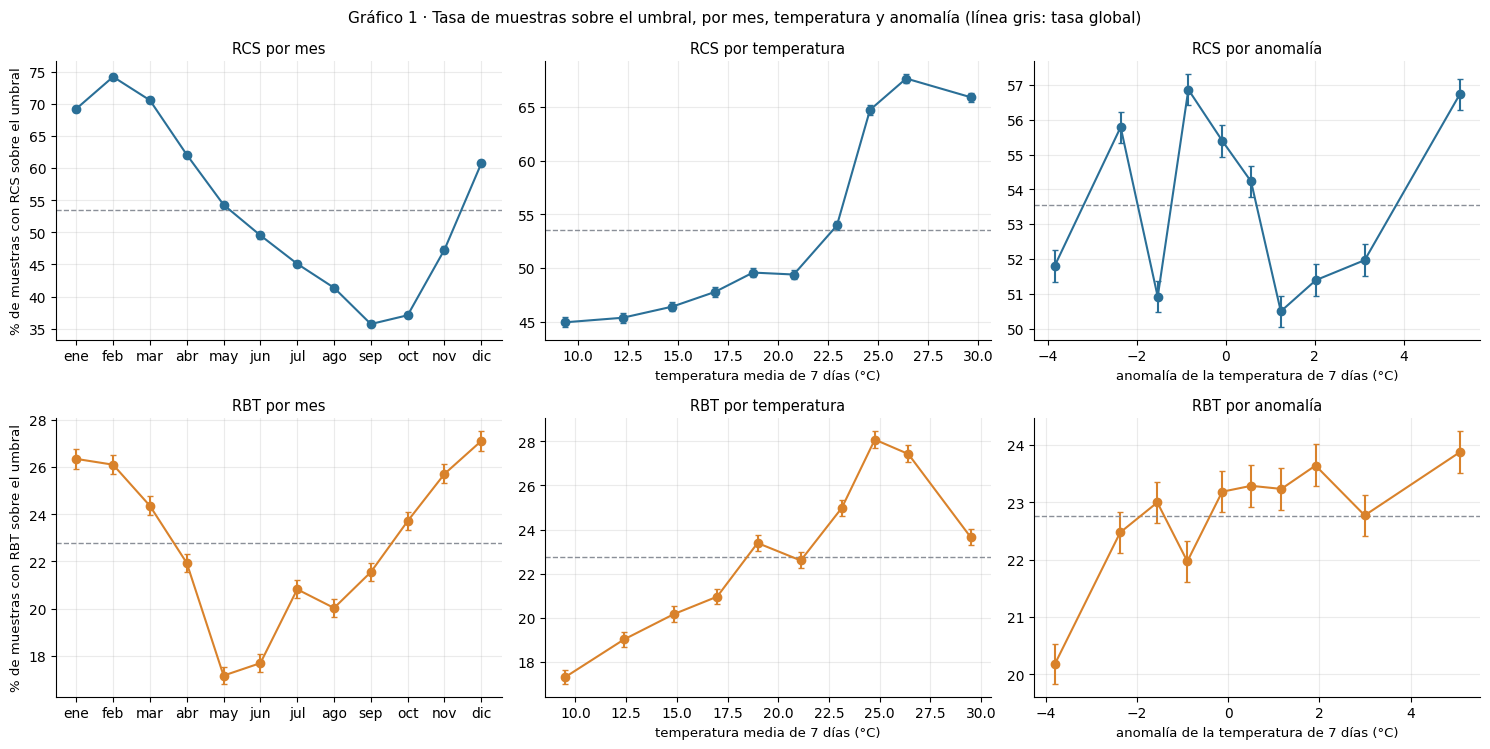

objetivo variable  primer decil (%)  último decil (%)
     RCS   temp_x              44.9              65.9
     RCS   anom_x              51.8              56.7
     RBT   temp_x              17.3              23.7
     RBT   anom_x              20.2              23.9


**En simple:** cada punto es el porcentaje de muestras que pasó el umbral en ese mes (izquierda), en ese tramo de temperatura (centro) o en ese tramo de anomalía (derecha). Si la curva sube con la temperatura pero se aplana en la columna de anomalía, el efecto que se ve en el centro es en buena parte la estación, no el calor en sí.

In [7]:
D7 = L.agregar_temperatura(d, temp, "media", 7)
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
fig, ax = plt.subplots(2, 3, figsize=(15, 7.6))
tabla_tasas = []
for i, (t, y) in enumerate(L.OBJETIVOS.items()):
    x = D7[D7[y].notna() & D7["temp_x"].notna()]
    tasa = x[y].mean()
    g = x.groupby("mes")[y].agg(["mean", "sum", "count"])
    lo, hi = wilson(g["sum"], g["count"])
    ax[i, 0].errorbar(g.index, 100 * g["mean"], yerr=[100 * (g["mean"] - lo), 100 * (hi - g["mean"])], fmt="o-", color=COLOR[t], capsize=2)
    ax[i, 0].set_xticks(range(1, 13)); ax[i, 0].set_xticklabels(MESES)
    ax[i, 0].set_ylabel(f"% de muestras con {t} sobre el umbral"); ax[i, 0].set_title(f"{t} por mes")
    for j, (col, rot) in enumerate([("temp_x", "temperatura media de 7 días (°C)"), ("anom_x", "anomalía de la temperatura de 7 días (°C)")], start=1):
        q = pd.qcut(x[col], 10, duplicates="drop")
        gg = x.groupby(q, observed=True).agg(xm=(col, "mean"), k=(y, "sum"), n=(y, "size"))
        lo, hi = wilson(gg["k"], gg["n"]); pm = gg["k"] / gg["n"]
        ax[i, j].errorbar(gg["xm"], 100 * pm, yerr=[100 * (pm - lo), 100 * (hi - pm)], fmt="o-", color=COLOR[t], capsize=2)
        ax[i, j].set_xlabel(rot); ax[i, j].set_title(f"{t} por " + ("temperatura" if col == "temp_x" else "anomalía"))
        tabla_tasas.append({"objetivo": t, "variable": col, "primer decil (%)": round(100 * pm.iloc[0], 1), "último decil (%)": round(100 * pm.iloc[-1], 1)})
    for j in range(3):
        ax[i, j].axhline(100 * tasa, color=GRIS, ls="--", lw=1)
fig.suptitle("Gráfico 1 · Tasa de muestras sobre el umbral, por mes, temperatura y anomalía (línea gris: tasa global)", fontsize=11)
fig.tight_layout()
guardar(fig, "01_tasa_positivos_mes_temperatura.png")
print(pd.DataFrame(tabla_tasas).to_string(index=False))
en_simple("cada punto es el porcentaje de muestras que pasó el umbral en ese mes (izquierda), en ese tramo de temperatura (centro) o en ese tramo de anomalía "
          "(derecha). Si la curva sube con la temperatura pero se aplana en la columna de anomalía, el efecto que se ve en el centro es en buena parte la estación, no el calor en sí.")

## 6 · Modelos anidados y validación temporal
Modelos, de menor a mayor (todos `Pipeline`: `StandardScaler` en las numéricas + `OneHotEncoder` en la industria + `LogisticRegression`):

| Modelo | Predictores |
|---|---|
| R0 | tasa global del entrenamiento (sin predictores) |
| R1 | industria (= tasa por industria) |
| M1 | industria + estación (sen, cos del día del año) |
| M2 | industria + temperatura absoluta, **sin** estación (muestra el efecto confundido) |
| M3 | industria + estación + **anomalía** de la temperatura (el modelo que responde a la pregunta del calor) |

La composición (lactosa, grasa, proteína) va en un modelo aparte (sección 9), porque no todas las filas la tienen.
Primero se elige la **regularización C** (y se compara `class_weight='balanced'`) en el modelo M3 con la validación rodante 2021-2023 (la prueba 2024-2026 se muestra al lado pero no decide).

In [8]:
GRID_C = [1e-5, 1e-4, 1e-3, 1e-2, 1.0, 100.0]
filas = []
for t, y in L.OBJETIVOS.items():
    x = DATOS[t]
    ent, ev = x[x["fecha"] < L.CORTE_PRUEBA], x[x["fecha"] >= L.CORTE_PRUEBA]
    for cw, C in [(None, c) for c in GRID_C] + [("balanced", 1.0)]:
        r = {"objetivo": t, "C": C, "class_weight": cw or "-"}
        v = L.validar_rodante(x, y, NUM_M3, CAT, C=C, class_weight=cw)
        r.update({"AUC valid": v["AUC"], "log-loss valid": v["log-loss"], "Brier valid": v["Brier"]})
        p, _ = L.ajustar_predecir(L.hacer_pipeline(NUM_M3, CAT, C=C, class_weight=cw), ent, ev, y, NUM_M3, CAT)
        m = L.metricas(ev[y], p)
        mm = L.matriz_umbral(ev[y], p, 0.5)
        r.update({"AUC prueba": m["AUC"], "log-loss prueba": m["log-loss"], "Brier prueba": m["Brier"], "sens@0,5": mm["sensibilidad"], "espec@0,5": mm["especificidad"],
                  "prob. media predicha": p.mean(), "tasa observada": ev[y].mean()})
        filas.append(r)
reg = pd.DataFrame(filas)
print(reg.round(4).to_string(index=False))
C_ELEG = {}
for t in L.OBJETIVOS:
    s = reg[(reg["objetivo"] == t) & (reg["class_weight"] == "-")]
    mejor = s["log-loss valid"].min()
    C_ELEG[t] = float(s[s["log-loss valid"] <= mejor + 2e-4]["C"].min())     # empate técnico → la más regularizada
print("\nC elegido (menor log-loss de validación rodante; si empatan por menos de 0,0002, el más regularizado):", C_ELEG)
RES["C"] = C_ELEG
reg.to_csv(SALIDA / "regularizacion_y_balanceo.csv", index=False, encoding="utf-8-sig")

objetivo        C class_weight  AUC valid  log-loss valid  Brier valid  AUC prueba  log-loss prueba  Brier prueba  sens@0,5  espec@0,5  prob. media predicha  tasa observada
     RCS   0.0000            -     0.6113          0.6829       0.2449      0.6858           0.6649        0.2360    0.8305     0.3765                0.5418          0.5425
     RCS   0.0001            -     0.6168          0.6726       0.2399      0.6915           0.6438        0.2259    0.7874     0.4661                0.5580          0.5425
     RCS   0.0010            -     0.6224          0.6717       0.2394      0.6914           0.6402        0.2243    0.7889     0.4662                0.5671          0.5425
     RCS   0.0100            -     0.6232          0.6722       0.2395      0.6900           0.6404        0.2244    0.7892     0.4640                0.5691          0.5425
     RCS   1.0000            -     0.6231          0.6724       0.2396      0.6894           0.6408        0.2246    0.7887     0.4643 

**Cómo leerlo.** Con cientos de miles de filas y pocos predictores, la regularización casi no cambia nada hasta que C es muy chico
(el coeficiente se encoge hacia 0 y el modelo se parece a la referencia). `class_weight='balanced'` casi no mueve el AUC (el orden de las
muestras es prácticamente el mismo). En **RBT**, que tiene pocos positivos (alrededor de una de cada cinco muestras), **empeora mucho el log-loss y el Brier y la probabilidad media predicha se aleja
de la tasa observada** (mirar las dos últimas columnas); a cambio, la sensibilidad a 0,5 pasa de cero a un valor útil. En **RCS**, donde las clases ya están casi equilibradas, cambia poco.
Reponderar las clases equivale a mover el umbral de decisión, y en RBT se paga con la probabilidad calibrada. Por eso la probabilidad se estima sin reponderar, y el compromiso
sensibilidad/especificidad se resuelve eligiendo el umbral (sección 7).

In [9]:
MODELOS = {
    "R1 industria": ([], CAT),
    "M1 estación + industria": (["sen", "cos"], CAT),
    "M2 temperatura (sin estación) + industria": (["temp_x"], CAT),
    "M3 estación + anomalía + industria": (NUM_M3, CAT),
}
AJ = {}          # (objetivo, modelo) → dict con pipeline, predicciones y filas
filas = []
for t, y in L.OBJETIVOS.items():
    x = DATOS[t]
    ent, pru = x[x["fecha"] < L.CORTE_PRUEBA], x[x["fecha"] >= L.CORTE_PRUEBA]
    tasa0 = ent[y].mean()
    m0 = L.metricas(pru[y], np.full(len(pru), tasa0))
    filas.append({"objetivo": t, "modelo": "R0 tasa global", **m0, "ECE": abs(pru[y].mean() - tasa0), "pendiente calib.": np.nan, "prob. media": tasa0, "tasa observada": pru[y].mean()})
    for nombre, (num, cat) in MODELOS.items():
        p, pipe = L.ajustar_predecir(L.hacer_pipeline(num, cat, C=C_ELEG[t]), ent, pru, y, num, cat)
        AJ[(t, nombre)] = {"pipe": pipe, "p": p, "y": pru[y].to_numpy(), "ent": ent, "pru": pru, "num": num, "cat": cat}
        m = L.metricas(pru[y], p); _, ece = L.calibracion(pru[y], p); pend, inter = L.pendiente_calibracion(pru[y], p)
        filas.append({"objetivo": t, "modelo": nombre, **m, "ECE": ece, "pendiente calib.": pend, "prob. media": p.mean(), "tasa observada": pru[y].mean()})
    # modelo con class_weight balanced, solo para el gráfico de calibración
    p, pipe = L.ajustar_predecir(L.hacer_pipeline(NUM_M3, CAT, C=C_ELEG[t], class_weight="balanced"), ent, pru, y, NUM_M3, CAT)
    AJ[(t, "M3 balanceado")] = {"pipe": pipe, "p": p, "y": pru[y].to_numpy(), "ent": ent, "pru": pru, "num": NUM_M3, "cat": CAT}
res = pd.DataFrame(filas)
res["Δ log-loss vs R1"] = res["log-loss"] - res.groupby("objetivo")["log-loss"].transform(lambda s: s[res.loc[s.index, "modelo"] == "R1 industria"].iloc[0])
print(f"Prueba temporal: entrenar hasta 2023, probar {L.CORTE_PRUEBA.year}-2026 (C elegido por objetivo: {C_ELEG}).")
print(res.round(4).to_string(index=False))
res.to_csv(SALIDA / "metricas_prueba_modelos_anidados.csv", index=False, encoding="utf-8-sig")
RES["tabla_main"] = res

Prueba temporal: entrenar hasta 2023, probar 2024-2026 (C elegido por objetivo: {'RCS': 0.001, 'RBT': 0.001}).
objetivo                                    modelo    AUC  log-loss  Brier    ECE  pendiente calib.  prob. media  tasa observada  Δ log-loss vs R1
     RCS                            R0 tasa global 0.5000    0.6898 0.2483 0.0110               NaN       0.5315          0.5425            0.0059
     RCS                              R1 industria 0.5673    0.6839 0.2454 0.0250            1.1572       0.5461          0.5425            0.0000
     RCS                   M1 estación + industria 0.6908    0.6404 0.2244 0.0491            1.5205       0.5657          0.5425           -0.0435
     RCS M2 temperatura (sin estación) + industria 0.6059    0.6755 0.2413 0.0328            1.6707       0.5426          0.5425           -0.0084
     RCS        M3 estación + anomalía + industria 0.6914    0.6402 0.2243 0.0495            1.5249       0.5671          0.5425           -0.0437
     RB

**Cómo leerlo.** AUC: probabilidad de que una muestra positiva reciba más probabilidad que una negativa (0,5 = azar). Log-loss y Brier: error
de las probabilidades (menor es mejor), se comparan con **R1**, el piso razonable (la tasa de cada industria). **Pendiente de calibración** (regresión de lo observado sobre el logit de lo predicho): 1 = bien calibrado; **más de 1 = el modelo es tímido** (sus probabilidades están demasiado cerca del promedio y lo real se
abre más); menos de 1 = exagera (probabilidades demasiado extremas). **ECE**: distancia media entre lo predicho y lo observado.

In [10]:
# Modelos con composición: aparte, en el subconjunto de filas que tienen lactosa, grasa y proteína (la falta de composición depende de
# la industria y del año, así que se compara contra los mismos modelos reajustados en ese subconjunto).
COMP = L.COMPOSICION
MOD_COMP = {
    "M1s estación + industria (subconjunto)": (["sen", "cos"], CAT),
    "M3s estación + anomalía + industria (subconjunto)": (NUM_M3, CAT),
    "C1 estación + composición + industria": (["sen", "cos"] + COMP, CAT),
    "C2 estación + anomalía + composición + industria": (NUM_M3 + COMP, CAT),
}
filas = []
SUB = {}
for t, y in L.OBJETIVOS.items():
    x = DATOS[t]
    cobertura = x[COMP].notna().all(axis=1).mean()
    xs = x[x[COMP].notna().all(axis=1)]
    SUB[t] = xs
    ent, pru = xs[xs["fecha"] < L.CORTE_PRUEBA], xs[xs["fecha"] >= L.CORTE_PRUEBA]
    print(f"{t}: con composición completa {100 * cobertura:.1f} % de las filas ({len(xs):,}); positivos {100 * xs[y].mean():.1f} % (sin composición: {100 * x.loc[~x.index.isin(xs.index), y].mean():.1f} %) "
          f"· entrenamiento {len(ent):,} · prueba {len(pru):,}")
    p1, _ = L.ajustar_predecir(L.hacer_pipeline([], CAT, C=C_ELEG[t]), ent, pru, y, [], CAT)
    filas.append({"objetivo": t, "modelo": "R1s industria (subconjunto)", **L.metricas(pru[y], p1), "ECE": L.calibracion(pru[y], p1)[1], "pendiente calib.": L.pendiente_calibracion(pru[y], p1)[0]})
    for nombre, (num, cat) in MOD_COMP.items():
        p, pipe = L.ajustar_predecir(L.hacer_pipeline(num, cat, C=C_ELEG[t]), ent, pru, y, num, cat)
        AJ[(t, nombre)] = {"pipe": pipe, "p": p, "y": pru[y].to_numpy(), "ent": ent, "pru": pru, "num": num, "cat": cat}
        filas.append({"objetivo": t, "modelo": nombre, **L.metricas(pru[y], p), "ECE": L.calibracion(pru[y], p)[1], "pendiente calib.": L.pendiente_calibracion(pru[y], p)[0]})
resc = pd.DataFrame(filas)
print()
print(resc.round(4).to_string(index=False))
resc.to_csv(SALIDA / "metricas_prueba_con_composicion.csv", index=False, encoding="utf-8-sig")
RES["tabla_comp"] = resc

RCS: con composición completa 82.8 % de las filas (389,425); positivos 55.7 % (sin composición: 43.4 %) · entrenamiento 240,839 · prueba 148,586


RBT: con composición completa 88.9 % de las filas (458,719); positivos 20.6 % (sin composición: 40.0 %) · entrenamiento 296,946 · prueba 161,773



objetivo                                            modelo    AUC  log-loss  Brier    ECE  pendiente calib.
     RCS                       R1s industria (subconjunto) 0.5431    0.6852 0.2461 0.0225            0.7619
     RCS            M1s estación + industria (subconjunto) 0.6724    0.6479 0.2281 0.0517            1.5372
     RCS M3s estación + anomalía + industria (subconjunto) 0.6727    0.6479 0.2281 0.0536            1.5361
     RCS             C1 estación + composición + industria 0.7207    0.6176 0.2145 0.0469            1.3118
     RCS  C2 estación + anomalía + composición + industria 0.7213    0.6175 0.2144 0.0477            1.3179
     RBT                       R1s industria (subconjunto) 0.5280    0.4793 0.1510 0.0374            0.5979
     RBT            M1s estación + industria (subconjunto) 0.5645    0.4758 0.1498 0.0353            0.8661
     RBT M3s estación + anomalía + industria (subconjunto) 0.5626    0.4763 0.1500 0.0363            0.8400
     RBT             C1 est

## 7 · Curva ROC, calibración y matriz de confusión
Gráfico 2. ROC (izquierda) y calibración (derecha) en la **prueba 2024-2026**. La calibración agrupa las muestras en diez grupos según la probabilidad que
el modelo les dio y compara con el porcentaje que realmente superó el umbral. En línea de puntos, M3 con `class_weight='balanced'`: ilustra qué se pierde al reponderar.

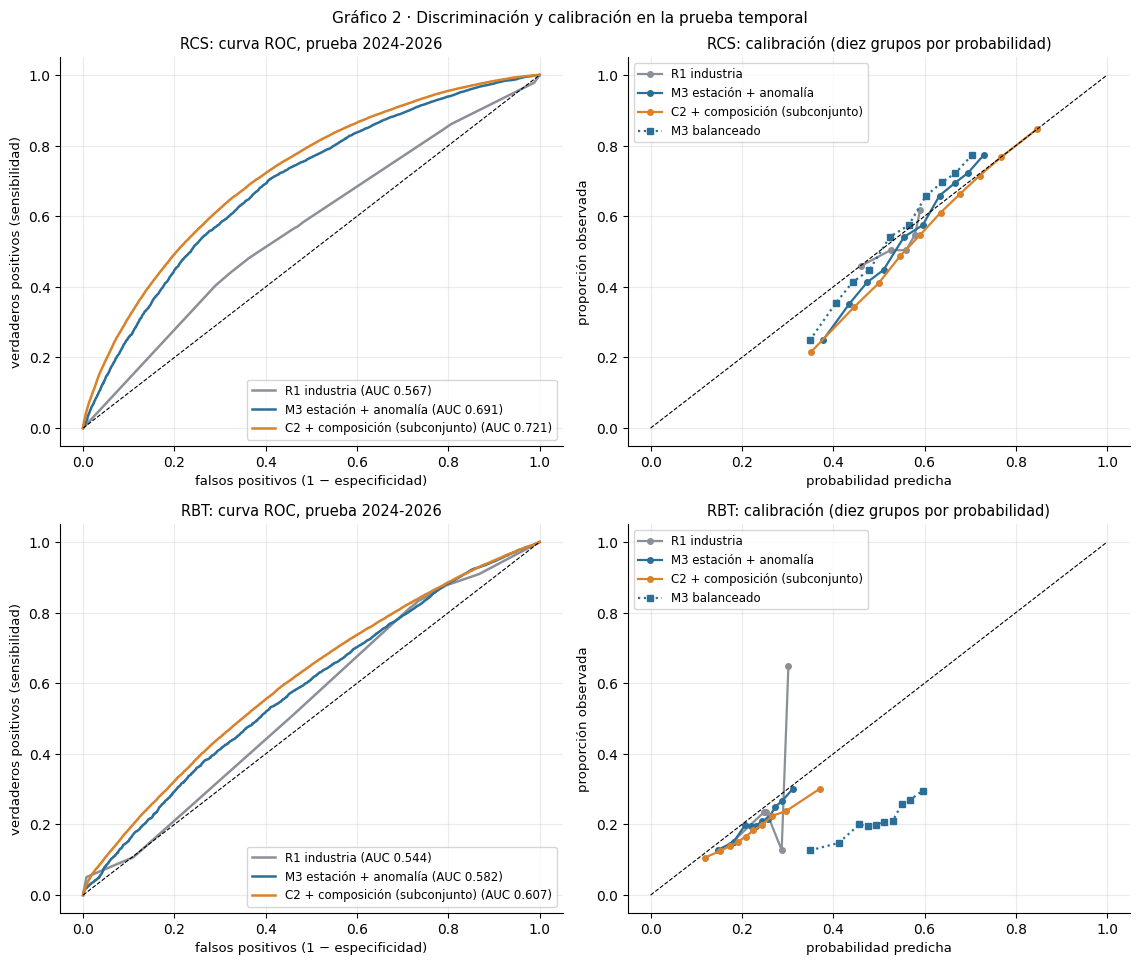

RCS calibración (prueba):
  R1 industria: ECE 0.025 · predicha por grupo [0.46, 0.53, 0.56, 0.58, 0.59] · observada [0.46, 0.5, 0.5, 0.55, 0.62]
  M3 estación + anomalía + industria: ECE 0.050 · predicha por grupo [0.38, 0.44, 0.47, 0.51, 0.56, 0.6, 0.63, 0.67, 0.69, 0.73] · observada [0.25, 0.35, 0.41, 0.45, 0.54, 0.57, 0.66, 0.7, 0.72, 0.77]
  C2 estación + anomalía + composición + industria: ECE 0.048 · predicha por grupo [0.35, 0.44, 0.5, 0.55, 0.59, 0.63, 0.68, 0.72, 0.77, 0.85] · observada [0.21, 0.34, 0.41, 0.49, 0.55, 0.61, 0.66, 0.72, 0.77, 0.85]
RBT calibración (prueba):
  R1 industria: ECE 0.038 · predicha por grupo [0.17, 0.25, 0.25, 0.29, 0.3] · observada [0.14, 0.23, 0.24, 0.13, 0.65]
  M3 estación + anomalía + industria: ECE 0.025 · predicha por grupo [0.15, 0.18, 0.21, 0.22, 0.23, 0.24, 0.26, 0.27, 0.29, 0.31] · observada [0.13, 0.15, 0.2, 0.19, 0.19, 0.21, 0.22, 0.25, 0.27, 0.3]
  C2 estación + anomalía + composición + industria: ECE 0.042 · predicha por grupo [0.12, 0

**En simple:** la curva ROC dice qué tan bien el modelo ordena las muestras de menos a más riesgosas (cuanto más arriba y a la izquierda, mejor; la diagonal es tirar una moneda). La calibración dice si la probabilidad se puede creer: si en el grupo al que el modelo le dio 60 % realmente el 60 % pasó el umbral, los puntos caen sobre la diagonal. Si los puntos quedan por debajo o por encima de la diagonal, el modelo está sobreestimando o subestimando el riesgo en esos años.

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(11.5, 9.8))
SERIES = [("R1 industria", GRIS, "-", "R1 industria"), ("M3 estación + anomalía + industria", AZUL, "-", "M3 estación + anomalía"),
          ("C2 estación + anomalía + composición + industria", NARANJA, "-", "C2 + composición (subconjunto)"), ("M3 balanceado", AZUL, ":", "M3 balanceado")]
for i, t in enumerate(L.OBJETIVOS):
    for nombre, col, ls, lab in SERIES:
        a = AJ[(t, nombre)]
        if "balanceado" not in nombre:
            fpr, tpr, _ = roc_curve(a["y"], a["p"])
            ax[i, 0].plot(fpr, tpr, color=col, ls=ls, lw=1.8, label=f"{lab} (AUC {L.metricas(a['y'], a['p'])['AUC']:.3f})")
        tab, ece = L.calibracion(a["y"], a["p"])
        ax[i, 1].plot(tab["predicha"], tab["observada"], "o" + ls if ls == "-" else "s:", color=col, lw=1.6, ms=4, label=lab)
    ax[i, 0].plot([0, 1], [0, 1], color="k", lw=0.8, ls="--")
    ax[i, 0].set_xlabel("falsos positivos (1 − especificidad)"); ax[i, 0].set_ylabel("verdaderos positivos (sensibilidad)")
    ax[i, 0].set_title(f"{t}: curva ROC, prueba 2024-2026"); ax[i, 0].legend(loc="lower right")
    lim = [0, 1]
    ax[i, 1].plot(lim, lim, color="k", lw=0.8, ls="--")
    ax[i, 1].set_xlabel("probabilidad predicha"); ax[i, 1].set_ylabel("proporción observada")
    ax[i, 1].set_title(f"{t}: calibración (diez grupos por probabilidad)"); ax[i, 1].legend(loc="upper left")
fig.suptitle("Gráfico 2 · Discriminación y calibración en la prueba temporal", fontsize=11)
fig.tight_layout()
guardar(fig, "02_roc_calibracion.png")
for t in L.OBJETIVOS:
    print(t, "calibración (prueba):")
    for nombre in ("R1 industria", "M3 estación + anomalía + industria", "C2 estación + anomalía + composición + industria"):
        tab, ece = L.calibracion(AJ[(t, nombre)]["y"], AJ[(t, nombre)]["p"])
        print(f"  {nombre}: ECE {ece:.3f} · predicha por grupo {tab['predicha'].round(2).tolist()} · observada {tab['observada'].round(2).tolist()}")
en_simple("la curva ROC dice qué tan bien el modelo ordena las muestras de menos a más riesgosas (cuanto más arriba y a la izquierda, mejor; la diagonal es tirar una moneda). "
          "La calibración dice si la probabilidad se puede creer: si en el grupo al que el modelo le dio 60 % realmente el 60 % pasó el umbral, los puntos caen sobre la diagonal. "
          "Si los puntos quedan por debajo o por encima de la diagonal, el modelo está sobreestimando o subestimando el riesgo en esos años.")

**Matriz de confusión y el compromiso sensibilidad/especificidad.** Una probabilidad se convierte en un «sí/no» con un umbral de decisión. Bajarlo detecta más positivos
(sube la **sensibilidad**) a costa de marcar más negativos como positivos (baja la **especificidad**); subirlo hace lo contrario. No hay un umbral «correcto»: depende
de cuánto cuesta no detectar una muestra mala frente a revisar una buena. Acá se toma como punto de partida el umbral de **Youden** calculado **en el entrenamiento**
(el que maximiza sensibilidad + especificidad − 1), se lo aplica a la prueba y se muestran otros cortes para ver el compromiso.

In [12]:
filas, tablas_umbral = [], []
for t in L.OBJETIVOS:
    for nombre in ("M3 estación + anomalía + industria", "C2 estación + anomalía + composición + industria"):
        a = AJ[(t, nombre)]; y = L.OBJETIVOS[t]
        cols = a["num"] + a["cat"]
        p_ent = a["pipe"].predict_proba(a["ent"][cols])[:, 1]
        u = L.umbral_youden(a["ent"][y], p_ent)
        mm = L.matriz_umbral(a["y"], a["p"], u)
        filas.append({"objetivo": t, "modelo": nombre, **mm})
        if nombre.startswith("C2") or nombre.startswith("M3"):
            for q in (0.1, 0.3, 0.5, 0.7, 0.9):
                tablas_umbral.append({"objetivo": t, "modelo": nombre[:2], **L.matriz_umbral(a["y"], a["p"], float(np.quantile(a["p"], q)))})
cm = pd.DataFrame(filas)
print("Matriz de confusión en la prueba 2024-2026, con el umbral de Youden del entrenamiento:")
print(cm.round(3).to_string(index=False))
print()
tu = pd.DataFrame(tablas_umbral)
print("Compromiso sensibilidad / especificidad al mover el umbral (cortes en los percentiles 10-90 de la probabilidad predicha):")
print(tu.round(3).to_string(index=False))
cm.to_csv(SALIDA / "matriz_confusion_umbral_youden.csv", index=False, encoding="utf-8-sig")
tu.to_csv(SALIDA / "compromiso_umbrales.csv", index=False, encoding="utf-8-sig")
RES["cm"] = cm

Matriz de confusión en la prueba 2024-2026, con el umbral de Youden del entrenamiento:
objetivo                                           modelo  umbral    VP    FN    FP    VN  sensibilidad  especificidad  precisión (VPP)  exactitud
     RCS               M3 estación + anomalía + industria   0.519 72013 22752 39140 40783         0.760          0.510            0.648      0.646
     RCS C2 estación + anomalía + composición + industria   0.549 64894 18360 30782 34550         0.779          0.529            0.678      0.669
     RBT               M3 estación + anomalía + industria   0.227 24720 12283 78099 60146         0.668          0.435            0.240      0.484
     RBT C2 estación + anomalía + composición + industria   0.223 17508 12110 57444 74711         0.591          0.565            0.234      0.570

Compromiso sensibilidad / especificidad al mover el umbral (cortes en los percentiles 10-90 de la probabilidad predicha):
objetivo modelo  umbral    VP    FN     FP     VN  sens

## 8 · Interpretación: odds ratio con intervalos por bootstrap por bloques
Los **odds ratio** salen de exponenciar los coeficientes: un OR de 1,10 por °C dice que cada grado de anomalía **multiplica por 1,10 las chances** (odds) de pasar el umbral,
a igualdad del resto. El modelo de interpretación usa la anomalía de la temperatura, **el mes** (en vez de sen/cos, para dar un OR por mes) y la industria, ajustado con
**todos los datos 2019-2026**. Los OR de mes y de industria se expresan **respecto del promedio** de los meses (o de las industrias).

**Intervalos.** Las filas no son independientes: muchas muestras comparten informe, día y tambo, y todas las industrias ven el mismo clima. Un intervalo calculado como si fueran
independientes sería demasiado angosto. Se usa **bootstrap por bloques**: se remuestrean **semanas completas** con reposición (300 réplicas) y se reajusta el modelo; el
intervalo es el percentil 2,5-97,5 de los OR. (Como los predictores solo dependen de la industria, el día y el mes, las filas se agrupan en celdas con peso: el ajuste es idéntico al
de las filas y el bootstrap rápido; se verifica abajo.) Queda sin captar la dependencia entre semanas vecinas: por eso se prueba también con bloques de 4 y 8 semanas.

In [13]:
def ajustar_or(x, t, num, cat, B=300, ancho=1, C=1.0):
    y = L.OBJETIVOS[t]
    cel = L.armar_celdas(x, y, ["cliente", "fecha", "mes"], extra=[c for c in num if c not in ("cliente", "fecha", "mes")])
    pipe = L.hacer_pipeline(num, cat, C=C)
    pipe.fit(cel[num + cat], cel["y"], lr__sample_weight=cel["w"])
    nombres = L.nombres_columnas(pipe)
    punto = L.coef_crudos(pipe, nombres)
    sal = L.bootstrap_bloques(pipe, cel[num + cat], cel["y"], cel["w"], L.bloques_de(cel["semana"], ancho), B=B, semilla=L.SEMILLA)
    return {"pipe": pipe, "nombres": nombres, "punto": punto, "boot": L.desescalar_matriz(pipe, sal), "celdas": len(cel) // 2}

def or_variable(o, nombre, escala=1.0):
    i = o["nombres"].index(nombre)
    b = o["boot"][:, i] * escala
    return float(np.exp(o["punto"].iloc[i] * escala)), float(np.exp(np.quantile(b, 0.025))), float(np.exp(np.quantile(b, 0.975)))

NUM_OR, CAT_OR = ["anom_x"], ["cliente", "mes"]
OR = {}
t0 = time.time()
for t in L.OBJETIVOS:
    OR[t] = ajustar_or(DATOS[t], t, NUM_OR, CAT_OR, B=300)
    print(f"{t}: {OR[t]['celdas']:,} celdas (industria × día) · bootstrap 300 réplicas listo")
print(f"{time.time() - t0:.0f} s")

# verificación: celdas vs filas
for t, y in L.OBJETIVOS.items():
    x = DATOS[t]
    pf = L.hacer_pipeline(NUM_OR, CAT_OR, C=1.0).fit(x[NUM_OR + CAT_OR], x[y].astype(int))
    cf = L.coef_crudos(pf)
    print(f"{t}: coeficiente de la anomalía, filas {cf['num__anom_x']:.5f} vs celdas {OR[t]['punto']['num__anom_x']:.5f} (diferencia {abs(cf['num__anom_x'] - OR[t]['punto']['num__anom_x']):.1e})")

RCS: 7,305 celdas (industria × día) · bootstrap 300 réplicas listo


RBT: 7,660 celdas (industria × día) · bootstrap 300 réplicas listo
9 s


RCS: coeficiente de la anomalía, filas -0.01056 vs celdas -0.01056 (diferencia 2.0e-06)


RBT: coeficiente de la anomalía, filas -0.00817 vs celdas -0.00820 (diferencia 2.1e-05)


In [14]:
# Efecto de la temperatura según qué se controla (ventana elegida por objetivo)
filas = []
for t in L.OBJETIVOS:
    x = DATOS[t]
    espec = {"(a) temperatura absoluta, solo industria (confunde estación y calor)": (["temp_x"], ["cliente"], "num__temp_x"),
             "(b) anomalía, solo industria": (["anom_x"], ["cliente"], "num__anom_x"),
             "(c) temperatura absoluta, industria + mes": (["temp_x"], CAT_OR, "num__temp_x"),
             "(d) anomalía, industria + mes (modelo de interpretación)": (NUM_OR, CAT_OR, "num__anom_x")}
    for nombre, (num, cat, var) in espec.items():
        o = OR[t] if nombre.startswith("(d)") else ajustar_or(x, t, num, cat, B=300)
        orr, lo, hi = or_variable(o, var)
        filas.append({"objetivo": t, "especificación": nombre, "OR por +1 °C": orr, "IC95 inf": lo, "IC95 sup": hi})
tt = pd.DataFrame(filas)
print("Odds ratio por +1 °C según lo que se controle (IC95 por bootstrap de semanas):")
print(tt.round(4).to_string(index=False))
tt.to_csv(SALIDA / "or_temperatura_segun_control.csv", index=False, encoding="utf-8-sig")
RES["control"] = tt
RES["or_calor"] = {t: or_variable(OR[t], "num__anom_x") for t in L.OBJETIVOS}
for t in L.OBJETIVOS:
    o, lo, hi = RES["or_calor"][t]
    print(f"{t}: anomalía ({ELEG[t][0]} de {ELEG[t][1]} días): OR por +1 °C = {o:.3f} [{lo:.3f}; {hi:.3f}] · por +3 °C = {o ** 3:.3f} [{lo ** 3:.3f}; {hi ** 3:.3f}]")

Odds ratio por +1 °C según lo que se controle (IC95 por bootstrap de semanas):
objetivo                                                       especificación  OR por +1 °C  IC95 inf  IC95 sup
     RCS (a) temperatura absoluta, solo industria (confunde estación y calor)        1.0298    1.0221    1.0383
     RCS                                         (b) anomalía, solo industria        0.9927    0.9795    1.0069
     RCS                            (c) temperatura absoluta, industria + mes        0.9910    0.9829    1.0013
     RCS             (d) anomalía, industria + mes (modelo de interpretación)        0.9895    0.9809    0.9999
     RBT (a) temperatura absoluta, solo industria (confunde estación y calor)        1.0191    1.0139    1.0246
     RBT                                         (b) anomalía, solo industria        0.9956    0.9871    1.0035
     RBT                            (c) temperatura absoluta, industria + mes        0.9934    0.9857    1.0004
     RBT             (d) 

In [15]:
# Odds ratio por mes y por industria (respecto del promedio), con IC95 por bootstrap de semanas
filas_forest = {}
for t in L.OBJETIVOS:
    o = OR[t]
    out = []
    orr, lo, hi = RES["or_calor"][t]
    out.append(("anomalía +1 °C", "calor", orr, lo, hi))
    niv, dev_p = L.or_desvio_categoria(o["punto"].to_numpy(), o["nombres"], "cat__mes_")
    _, dev_b = L.or_desvio_categoria(o["boot"], o["nombres"], "cat__mes_")
    for k in sorted(range(len(niv)), key=lambda k: int(niv[k])):
        out.append((MESES[int(niv[k]) - 1], "mes", float(np.exp(dev_p[0, k])), float(np.exp(np.quantile(dev_b[:, k], 0.025))), float(np.exp(np.quantile(dev_b[:, k], 0.975)))))
    niv, dev_p = L.or_desvio_categoria(o["punto"].to_numpy(), o["nombres"], "cat__cliente_")
    _, dev_b = L.or_desvio_categoria(o["boot"], o["nombres"], "cat__cliente_")
    for k in sorted(range(len(niv)), key=lambda k: niv[k]):
        out.append((niv[k], "industria", float(np.exp(dev_p[0, k])), float(np.exp(np.quantile(dev_b[:, k], 0.025))), float(np.exp(np.quantile(dev_b[:, k], 0.975)))))
    filas_forest[t] = pd.DataFrame(out, columns=["término", "grupo", "OR", "IC95 inf", "IC95 sup"])
    print(f"{t} — odds ratio (mes e industria: respecto del promedio de sus niveles):")
    print(filas_forest[t].round(3).to_string(index=False)); print()
    filas_forest[t].to_csv(SALIDA / f"odds_ratio_{t.lower()}.csv", index=False, encoding="utf-8-sig")
RES["forest"] = filas_forest

RCS — odds ratio (mes e industria: respecto del promedio de sus niveles):
       término     grupo    OR  IC95 inf  IC95 sup
anomalía +1 °C     calor 0.989     0.981     1.000
           ene       mes 1.899     1.634     2.310
           feb       mes 2.518     2.186     3.010
           mar       mes 2.074     1.778     2.435
           abr       mes 1.396     1.184     1.642
           may       mes 0.991     0.880     1.105
           jun       mes 0.806     0.689     0.950
           jul       mes 0.684     0.578     0.800
           ago       mes 0.580     0.522     0.644
           sep       mes 0.463     0.409     0.521
           oct       mes 0.504     0.457     0.553
           nov       mes 0.757     0.671     0.873
           dic       mes 1.288     1.143     1.435
       IND-103 industria 0.984     0.423     1.294
        IND-29 industria 1.054     1.006     1.166
        IND-30 industria 1.200     1.132     1.332
        IND-51 industria 1.014     0.926     1.209
        

Gráfico 3. Odds ratio con intervalo de 95 % (bootstrap por bloques de semanas). La línea vertical en 1 es «sin efecto». Arriba el efecto de **+1 °C de anomalía**; después los
meses y las industrias, cada uno relativo al promedio de los de su grupo. Eje en escala logarítmica.

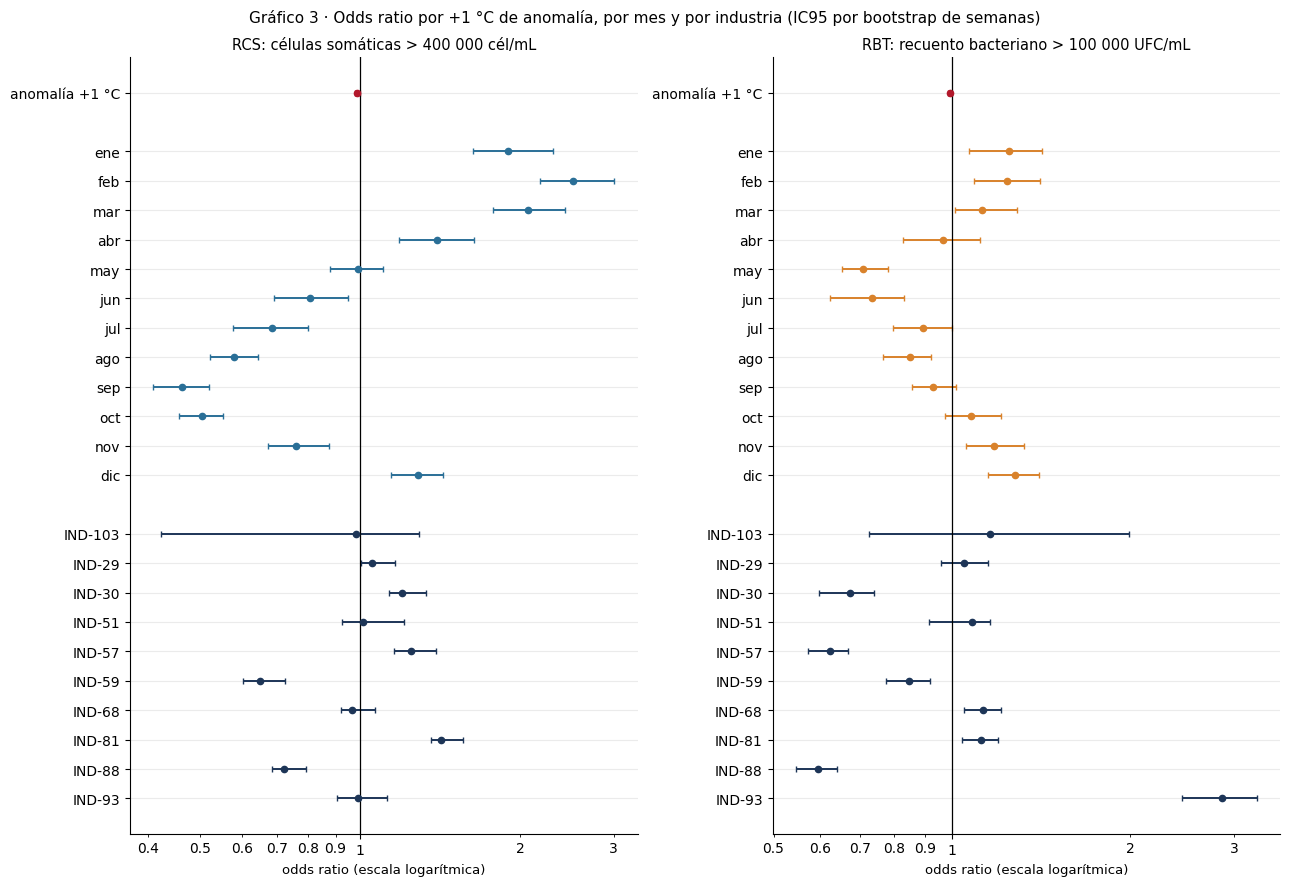

**En simple:** cada punto dice cuántas veces cambian las chances de pasar el umbral: 1 es «igual que el promedio», más de 1 es más riesgo, menos de 1 es menos. La barra es la incertidumbre: si cruza el 1, no se puede asegurar que haya diferencia. El primer renglón es el efecto de un grado más de calor que lo habitual para la fecha, con la estación ya descontada; los meses muestran la estacionalidad pura y las industrias, cuánto cambia el riesgo de una a otra.

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 9), sharey=False)
for k, t in enumerate(L.OBJETIVOS):
    f = filas_forest[t].reset_index(drop=True)
    ypos, pos = [], 0
    for g, sub in f.groupby("grupo", sort=False):
        for i in sub.index:
            ypos.append(pos); pos += 1
        pos += 1
    f["y"] = ypos
    for g, col in [("calor", "#b2182b"), ("mes", COLOR[t]), ("industria", OSCURO)]:
        s = f[f["grupo"] == g]
        ax[k].errorbar(s["OR"], s["y"], xerr=[s["OR"] - s["IC95 inf"], s["IC95 sup"] - s["OR"]], fmt="o", color=col, capsize=2.5, ms=4.5, lw=1.4)
    ax[k].axvline(1, color="k", lw=0.9)
    ax[k].set_xscale("log"); ax[k].set_yticks(f["y"]); ax[k].set_yticklabels(f["término"]); ax[k].invert_yaxis()
    ax[k].set_xlabel("odds ratio (escala logarítmica)"); ax[k].set_title(f"{t}: {NOMBRE[t]}")
    ax[k].xaxis.set_major_formatter(mt.FormatStrFormatter("%.2g"))
    ax[k].xaxis.set_minor_formatter(mt.FormatStrFormatter("%.2g"))
fig.suptitle("Gráfico 3 · Odds ratio por +1 °C de anomalía, por mes y por industria (IC95 por bootstrap de semanas)", fontsize=11)
fig.tight_layout()
guardar(fig, "03_odds_ratio.png")
en_simple("cada punto dice cuántas veces cambian las chances de pasar el umbral: 1 es «igual que el promedio», más de 1 es más riesgo, menos de 1 es menos. La barra es la incertidumbre: "
          "si cruza el 1, no se puede asegurar que haya diferencia. El primer renglón es el efecto de un grado más de calor que lo habitual para la fecha, con la estación ya descontada; los meses muestran la estacionalidad pura y las industrias, cuánto cambia el riesgo de una a otra.")

In [17]:
# Robustez del efecto del calor: ventana, ancho del bloque, y solo fechas exactas (no de creación del archivo)
filas = []
for t, y in L.OBJETIVOS.items():
    for est, n in VENTANAS:
        x = base_objetivo(t, est, n)
        o = ajustar_or(x, t, NUM_OR, CAT_OR, B=200)
        orr, lo, hi = or_variable(o, "num__anom_x")
        filas.append({"objetivo": t, "variante": f"ventana {est} {n} d", "OR por +1 °C": orr, "IC95 inf": lo, "IC95 sup": hi})
    x = DATOS[t]
    for ancho in (4, 8):
        o = ajustar_or(x, t, NUM_OR, CAT_OR, B=200, ancho=ancho)
        orr, lo, hi = or_variable(o, "num__anom_x")
        filas.append({"objetivo": t, "variante": f"bloques de {ancho} semanas", "OR por +1 °C": orr, "IC95 inf": lo, "IC95 sup": hi})
    xf = x[x["fecha_fina"]]
    o = ajustar_or(xf, t, NUM_OR, CAT_OR, B=200)
    orr, lo, hi = or_variable(o, "num__anom_x")
    filas.append({"objetivo": t, "variante": f"solo fecha exacta ({len(xf):,} filas)", "OR por +1 °C": orr, "IC95 inf": lo, "IC95 sup": hi})
    xf = x[x["fecha"] < L.CORTE_PRUEBA]
    o = ajustar_or(xf, t, NUM_OR, CAT_OR, B=200)
    orr, lo, hi = or_variable(o, "num__anom_x")
    filas.append({"objetivo": t, "variante": "solo entrenamiento (hasta 2023)", "OR por +1 °C": orr, "IC95 inf": lo, "IC95 sup": hi})
rob = pd.DataFrame(filas)
print("Robustez del OR por +1 °C de anomalía (con mes e industria; 200 réplicas):")
print(rob.round(4).to_string(index=False))
rob.to_csv(SALIDA / "or_calor_robustez.csv", index=False, encoding="utf-8-sig")
RES["robustez"] = rob

Robustez del OR por +1 °C de anomalía (con mes e industria; 200 réplicas):
objetivo                          variante  OR por +1 °C  IC95 inf  IC95 sup
     RCS                 ventana media 3 d        0.9904    0.9776    1.0039
     RCS                 ventana media 7 d        0.9980    0.9810    1.0181
     RCS                ventana media 14 d        1.0164    0.9941    1.0419
     RCS                   ventana max 3 d        0.9895    0.9808    1.0000
     RCS                   ventana max 7 d        0.9959    0.9859    1.0087
     RCS                  ventana max 14 d        1.0102    0.9951    1.0226
     RCS              bloques de 4 semanas        0.9895    0.9799    1.0009
     RCS              bloques de 8 semanas        0.9895    0.9783    1.0009
     RCS solo fecha exacta (246,730 filas)        0.9878    0.9798    0.9973
     RCS   solo entrenamiento (hasta 2023)        0.9904    0.9821    0.9996
     RBT                 ventana media 3 d        0.9979    0.9870    1.0074
 

## 9 · Composición: la señal de mastitis (lactosa)
Más células somáticas, menos lactosa: la mastitis daña la glándula y la lactosa de la leche baja. Se ajusta el modelo **C2** (estación + anomalía + composición + industria) en el subconjunto con lactosa, grasa y proteína.
**Aclaración:** lactosa, grasa y proteína son análisis aparte de las células y de las bacterias, no derivan del objetivo, pero **no son causas**; la relación es
una señal de que el tambo tiene mastitis, útil para estimar el riesgo, y no prueba que la lactosa baje por sí sola el recuento. Los OR se calculan por +0,1 g/100 g de cada componente (bootstrap por semanas, 150 réplicas, ajustado con todas las filas del subconjunto).

In [18]:
NUM_C2 = NUM_M3 + COMP
OR_COMP = {}
t0 = time.time()
for t, y in L.OBJETIVOS.items():
    xs = SUB[t]
    pipe = L.hacer_pipeline(NUM_C2, CAT, C=1.0).fit(xs[NUM_C2 + CAT], xs[y].astype(int))
    sal = L.bootstrap_bloques(pipe, xs[NUM_C2 + CAT], xs[y].astype(int).to_numpy(), np.ones(len(xs)), L.bloques_de(xs["semana"]), B=150, semilla=L.SEMILLA)
    nombres = L.nombres_columnas(pipe); punto = L.coef_crudos(pipe, nombres); boot = L.desescalar_matriz(pipe, sal)
    OR_COMP[t] = {"pipe": pipe, "nombres": nombres, "punto": punto, "boot": boot}
    filas = []
    for var, esc, lab in [("num__lactosa", 0.1, "lactosa +0,1 g/100 g"), ("num__grasa", 0.1, "grasa +0,1 g/100 g"), ("num__proteina", 0.1, "proteína +0,1 g/100 g"), ("num__anom_x", 1.0, "anomalía +1 °C")]:
        o, lo, hi = or_variable(OR_COMP[t], var, esc)
        filas.append({"término": lab, "OR": o, "IC95 inf": lo, "IC95 sup": hi})
    tab = pd.DataFrame(filas)
    print(f"{t}: odds ratio del modelo con composición (filas {len(xs):,}; IC95 por bootstrap de semanas):")
    print(tab.round(3).to_string(index=False)); print()
    tab.assign(objetivo=t).to_csv(SALIDA / f"odds_ratio_composicion_{t.lower()}.csv", index=False, encoding="utf-8-sig")
    OR_COMP[t]["tabla"] = tab
print(f"{time.time() - t0:.0f} s")
RES["or_lactosa"] = {t: OR_COMP[t]["tabla"].iloc[0][["OR", "IC95 inf", "IC95 sup"]].astype(float).tolist() for t in L.OBJETIVOS}

RCS: odds ratio del modelo con composición (filas 389,425; IC95 por bootstrap de semanas):
              término    OR  IC95 inf  IC95 sup
 lactosa +0,1 g/100 g 0.699     0.687     0.710
   grasa +0,1 g/100 g 1.043     1.037     1.048
proteína +0,1 g/100 g 1.022     1.009     1.039
       anomalía +1 °C 0.990     0.978     1.001



RBT: odds ratio del modelo con composición (filas 458,719; IC95 por bootstrap de semanas):
              término    OR  IC95 inf  IC95 sup
 lactosa +0,1 g/100 g 0.813     0.803     0.824
   grasa +0,1 g/100 g 1.014     1.011     1.018
proteína +0,1 g/100 g 0.990     0.977     1.006
       anomalía +1 °C 0.997     0.989     1.005

144 s


Gráfico 4. Probabilidad predicha según la lactosa. La curva es la **dependencia parcial** del modelo C2 ajustado hasta 2023 y evaluado en la prueba 2024-2026: para cada valor de lactosa se
asigna ese valor a todas las muestras de prueba (el resto queda como está) y se promedia la probabilidad predicha. Los puntos son la proporción observada de positivos en diez grupos de lactosa de la prueba.

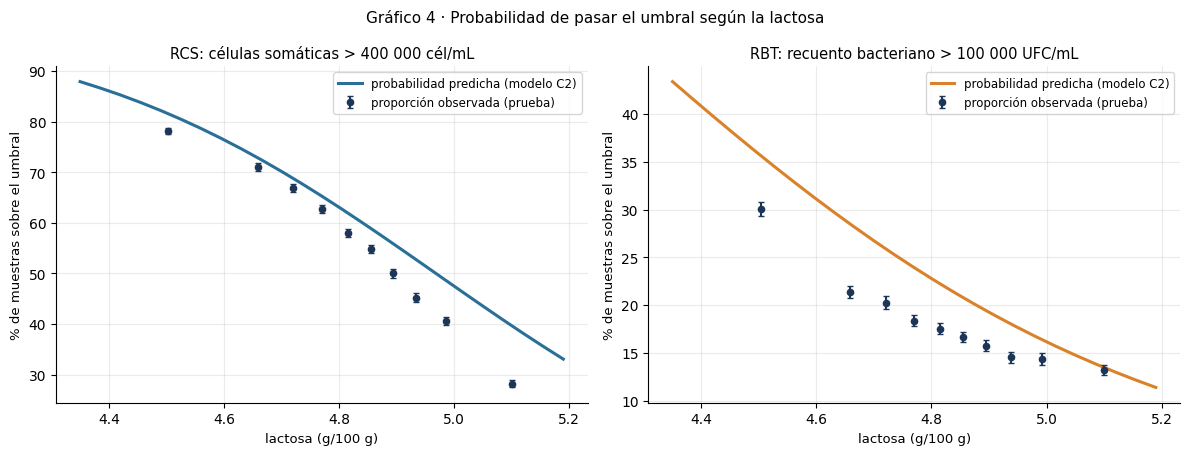

RCS: la probabilidad predicha pasa de 87.9 % con lactosa 4.35 a 33.1 % con lactosa 5.19 g/100 g
RBT: la probabilidad predicha pasa de 43.4 % con lactosa 4.35 a 11.4 % con lactosa 5.19 g/100 g


**En simple:** la curva muestra cuánto cambia, en promedio, la probabilidad de pasar el umbral cuando solo cambia la lactosa de la muestra. Si baja al subir la lactosa (más células con menos lactosa), es la huella de la mastitis; los puntos son lo que pasó de verdad y deberían acompañar la curva. Es una señal asociada, no una causa.

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
res_lact = {}
for k, t in enumerate(L.OBJETIVOS):
    y = L.OBJETIVOS[t]
    a = AJ[(t, "C2 estación + anomalía + composición + industria")]
    pru = a["pru"]; cols = a["num"] + a["cat"]
    q = pru["lactosa"].quantile([0.01, 0.99]).to_numpy()
    grilla = np.linspace(q[0], q[1], 25)
    muestra = pru.sample(min(20000, len(pru)), random_state=L.SEMILLA)[cols]
    pd_ = []
    for g in grilla:
        z = muestra.copy(); z["lactosa"] = g
        pd_.append(a["pipe"].predict_proba(z)[:, 1].mean())
    obs = pru.groupby(pd.qcut(pru["lactosa"], 10, duplicates="drop"), observed=True).agg(l=("lactosa", "mean"), k=(y, "sum"), n=(y, "size"))
    lo, hi = wilson(obs["k"], obs["n"]); pm = obs["k"] / obs["n"]
    ax[k].plot(grilla, 100 * np.array(pd_), color=COLOR[t], lw=2.2, label="probabilidad predicha (modelo C2)")
    ax[k].errorbar(obs["l"], 100 * pm, yerr=[100 * (pm - lo), 100 * (hi - pm)], fmt="o", color=OSCURO, capsize=2, ms=4.5, label="proporción observada (prueba)")
    ax[k].set_xlabel("lactosa (g/100 g)"); ax[k].set_ylabel("% de muestras sobre el umbral"); ax[k].set_title(f"{t}: {NOMBRE[t]}"); ax[k].legend(loc="best")
    res_lact[t] = (float(pd_[0]), float(pd_[-1]), float(grilla[0]), float(grilla[-1]))
fig.suptitle("Gráfico 4 · Probabilidad de pasar el umbral según la lactosa", fontsize=11)
fig.tight_layout()
guardar(fig, "04_probabilidad_vs_lactosa.png")
for t, (p0, p1, g0, g1) in res_lact.items():
    print(f"{t}: la probabilidad predicha pasa de {100 * p0:.1f} % con lactosa {g0:.2f} a {100 * p1:.1f} % con lactosa {g1:.2f} g/100 g")
RES["lactosa_pd"] = res_lact
en_simple("la curva muestra cuánto cambia, en promedio, la probabilidad de pasar el umbral cuando solo cambia la lactosa de la muestra. Si baja al subir la lactosa (más células con menos lactosa), "
          "es la huella de la mastitis; los puntos son lo que pasó de verdad y deberían acompañar la curva. Es una señal asociada, no una causa.")

## 10 · Una industria afuera (`GroupKFold` por cliente)
Para ver si el modelo sirve en una industria que no vio, se entrena con las otras nueve y se prueba en la que quedó afuera (en cada fila). Como la industria nueva no tiene
su propio nivel, el modelo **no lleva industria** (estación; estación + anomalía; y estación + anomalía + composición) y se lo compara con la tasa global de las otras industrias. Se informa el AUC **dentro** de la
industria dejada afuera, el log-loss y el Brier, y el **sesgo** (probabilidad media predicha menos la tasa observada): ahí se ve cuánto pesa el nivel propio de cada industria.

In [20]:
def loio(t):
    y = L.OBJETIVOS[t]
    x = DATOS[t]
    modelos = {"S1 estación": (["sen", "cos"], False), "S2 estación + anomalía": (NUM_M3, False), "S3 estación + anomalía + composición": (NUM_C2, True)}
    gkf = GroupKFold(n_splits=x["cliente"].nunique())
    filas = []
    for ent_idx, te_idx in gkf.split(x, groups=x["cliente"]):
        ent, te = x.iloc[ent_idx], x.iloc[te_idx]
        ind = te["cliente"].unique()
        assert len(ind) == 1
        fila = {"industria": ind[0], "filas": len(te), "tasa observada": te[y].mean(), "tasa ref. (otras industrias)": ent[y].mean()}
        mr = L.metricas(te[y], np.full(len(te), ent[y].mean()))
        fila["Brier ref."] = mr["Brier"]; fila["log-loss ref."] = mr["log-loss"]
        for nombre, (num, comp) in modelos.items():
            e2, t2 = (ent[ent[COMP].notna().all(axis=1)], te[te[COMP].notna().all(axis=1)]) if comp else (ent, te)
            if len(t2) < 200 or t2[y].nunique() < 2:
                fila[f"AUC {nombre[:2]}"] = np.nan; fila[f"skill Brier {nombre[:2]}"] = np.nan; fila[f"sesgo {nombre[:2]}"] = np.nan
                continue
            p, _ = L.ajustar_predecir(L.hacer_pipeline(num, [], C=C_ELEG[t]), e2, t2, y, num, [])
            m = L.metricas(t2[y], p)
            br = L.metricas(t2[y], np.full(len(t2), e2[y].mean()))["Brier"]
            fila[f"AUC {nombre[:2]}"] = m["AUC"]; fila[f"skill Brier {nombre[:2]}"] = 1 - m["Brier"] / br; fila[f"sesgo {nombre[:2]}"] = p.mean() - t2[y].mean()
        filas.append(fila)
    return pd.DataFrame(filas)

LOIO = {}
for t in L.OBJETIVOS:
    t0 = time.time()
    LOIO[t] = loio(t)
    print(f"\n{t}: una industria afuera (skill Brier = 1 − Brier del modelo / Brier de la tasa global; > 0 mejora la referencia; sesgo = media predicha − observada) · {time.time() - t0:.0f} s")
    f = LOIO[t].copy()
    print(f.round(3).to_string(index=False))
    w = f["filas"]
    resumen = {c: float(np.nansum(f[c] * w) / w[f[c].notna()].sum()) for c in f.columns if c.startswith(("AUC", "skill"))}
    print("Promedio ponderado por filas:", {k: round(v, 3) for k, v in resumen.items()})
    f.to_csv(SALIDA / f"industria_afuera_{t.lower()}.csv", index=False, encoding="utf-8-sig")
    LOIO[t].attrs["resumen"] = resumen
RES["loio"] = LOIO


RCS: una industria afuera (skill Brier = 1 − Brier del modelo / Brier de la tasa global; > 0 mejora la referencia; sesgo = media predicha − observada) · 4 s
industria  filas  tasa observada  tasa ref. (otras industrias)  Brier ref.  log-loss ref.  AUC S1  skill Brier S1  sesgo S1  AUC S2  skill Brier S2  sesgo S2  AUC S3  skill Brier S3  sesgo S3
   IND-68 138914           0.518                         0.543       0.250          0.694   0.654           0.070     0.023   0.654           0.071     0.022   0.699           0.118    -0.007
   IND-81 138220           0.607                         0.506       0.249          0.691   0.626           0.040    -0.104   0.627           0.041    -0.104   0.691           0.107    -0.068
   IND-88  67706           0.449                         0.550       0.258          0.709   0.670           0.082     0.099   0.671           0.083     0.099   0.676           0.104    -0.005
   IND-29  45921           0.544                         0.535       0.248


RBT: una industria afuera (skill Brier = 1 − Brier del modelo / Brier de la tasa global; > 0 mejora la referencia; sesgo = media predicha − observada) · 5 s
industria  filas  tasa observada  tasa ref. (otras industrias)  Brier ref.  log-loss ref.  AUC S1  skill Brier S1  sesgo S1  AUC S2  skill Brier S2  sesgo S2  AUC S3  skill Brier S3  sesgo S3
   IND-81 178103           0.248                         0.217       0.187          0.563   0.540           0.003    -0.031   0.540           0.003    -0.031   0.577           0.017    -0.038
   IND-68 126675           0.249                         0.221       0.188          0.564   0.547           0.005    -0.029   0.549           0.005    -0.029   0.640           0.037    -0.021
   IND-88  54423           0.149                         0.237       0.135          0.445   0.555           0.006     0.086   0.559           0.006     0.086   0.588           0.045     0.053
   IND-59  47182           0.204                         0.230       0.163

**Cómo leerlo.** El AUC por industria dice si, dentro de esa industria, el modelo ordena bien las muestras sin conocer su nivel. El *skill* del Brier se mide contra la tasa global de las otras industrias:
si es negativo, el modelo sin la industria es **peor que ese promedio simple**: pasa cuando el nivel propio de la industria (que el modelo no conoce) pesa más que la señal de estación y temperatura.
El sesgo muestra qué tan lejos queda el nivel medio predicho del real.

## 11 · Sensibilidad al umbral
¿Cambia la historia con otro corte? Se reajusta M3 y R1 con umbrales alternativos de cada recuento (mismo entrenamiento y prueba) y se compara el AUC y la mejora del Brier respecto de R1.

In [21]:
filas = []
for t, col, umbrales in [("RCS", "celulas_somaticas", (300, 400, 500, 600)), ("RBT", "rbt_corr", (50, 100, 200))]:
    x = DATOS[t].copy()
    for u in umbrales:
        x["yy"] = (x[col] > u).astype(float)
        ent, pru = x[x["fecha"] < L.CORTE_PRUEBA], x[x["fecha"] >= L.CORTE_PRUEBA]
        r1, _ = L.ajustar_predecir(L.hacer_pipeline([], CAT, C=C_ELEG[t]), ent, pru, "yy", [], CAT)
        m3, _ = L.ajustar_predecir(L.hacer_pipeline(NUM_M3, CAT, C=C_ELEG[t]), ent, pru, "yy", NUM_M3, CAT)
        a, b = L.metricas(pru["yy"], r1), L.metricas(pru["yy"], m3)
        filas.append({"objetivo": t, "umbral": u, "% positivos": 100 * x["yy"].mean(), "AUC R1": a["AUC"], "AUC M3": b["AUC"], "Brier R1": a["Brier"], "Brier M3": b["Brier"], "mejora Brier (%)": 100 * (1 - b["Brier"] / a["Brier"])})
sens = pd.DataFrame(filas)
print(sens.round(4).to_string(index=False))
sens.to_csv(SALIDA / "sensibilidad_umbral.csv", index=False, encoding="utf-8-sig")

objetivo  umbral  % positivos  AUC R1  AUC M3  Brier R1  Brier M3  mejora Brier (%)
     RCS     300      78.0144  0.5267  0.6794    0.1754    0.1658            5.4535
     RCS     400      53.5553  0.5673  0.6914    0.2454    0.2243            8.5949
     RCS     500      33.2538  0.5869  0.6975    0.2225    0.2051            7.7900
     RCS     600      20.3421  0.6093  0.7001    0.1669    0.1578            5.4863
     RBT      50      47.9601  0.5468  0.6129    0.2497    0.2446            2.0475
     RBT     100      22.7621  0.5439  0.5822    0.1661    0.1648            0.7645
     RBT     200      11.9905  0.5498  0.5669    0.0968    0.0965            0.3211


## 12 · Conclusiones (generadas con los resultados de arriba)

In [22]:
def veredicto(o, lo, hi):
    if lo > 1: return "el intervalo queda por encima de 1: hay una asociación con más riesgo"
    if hi < 1: return "el intervalo queda apenas por debajo de 1: el efecto es mínimo y de signo contrario al esperado (no hay evidencia de que el calor suba el riesgo)"
    return "el intervalo incluye 1: no hay evidencia de que el calor, con la estación descontada, cambie el riesgo"

tm, tc = RES["tabla_main"], RES["tabla_comp"]
def g(df, t, modelo, col):
    return float(df[(df["objetivo"] == t) & (df["modelo"] == modelo)][col].iloc[0])

lineas = ["**Resumen de resultados (prueba temporal 2024-2026, entrenando hasta 2023).**", ""]
for t in L.OBJETIVOS:
    o, lo, hi = RES["or_calor"][t]
    e, n = RES["ventana"][t]
    r1 = "R1 industria"; m3 = "M3 estación + anomalía + industria"; c2 = "C2 estación + anomalía + composición + industria"; c1s = "M3s estación + anomalía + industria (subconjunto)"
    lineas += [
        f"**{t} ({NOMBRE[t]}; {100 * RES['tasa_global'][t]:.0f} % de positivos).**",
        f"* **Calor.** Con la estación y la industria controladas, +1 °C de anomalía ({e} de {n} días) da un OR de {o:.3f} [IC95 {lo:.3f}; {hi:.3f}] (+3 °C: {o ** 3:.2f} [{lo ** 3:.2f}; {hi ** 3:.2f}]): {veredicto(o, lo, hi)}.",
        f"* **Discriminación.** AUC en la prueba: referencia por industria {g(tm, t, r1, 'AUC'):.3f}; estación + industria {g(tm, t, 'M1 estación + industria', 'AUC'):.3f}; con anomalía (M3) {g(tm, t, m3, 'AUC'):.3f}. "
        f"Con composición (subconjunto): {g(tc, t, c1s, 'AUC'):.3f} sin composición contra {g(tc, t, c2, 'AUC'):.3f} con ella.",
        f"* **Probabilidad.** Brier de M3 {g(tm, t, m3, 'Brier'):.4f} contra {g(tm, t, r1, 'Brier'):.4f} de la referencia por industria (log-loss {g(tm, t, m3, 'log-loss'):.4f} contra {g(tm, t, r1, 'log-loss'):.4f}); "
        f"pendiente de calibración de M3 {g(tm, t, m3, 'pendiente calib.'):.2f} (más de 1 = el modelo es tímido: sus probabilidades quedan más cerca del promedio de lo que muestran los datos), ECE {g(tm, t, m3, 'ECE'):.3f}; probabilidad media predicha {g(tm, t, m3, 'prob. media'):.3f} contra {g(tm, t, m3, 'tasa observada'):.3f} observada.",
    ]
    rb = RES["robustez"][RES["robustez"]["objetivo"] == t]
    n_var, n_sube, n_baja = len(rb), int((rb["IC95 inf"] > 1).sum()), int((rb["IC95 sup"] < 1).sum())
    ctl = RES["control"]; ca = ctl[(ctl["objetivo"] == t) & ctl["especificación"].str.startswith("(a)")].iloc[0]
    lineas.append(f"* **Robustez del calor.** De {n_var} variantes (ventanas, bloques, fechas exactas, solo entrenamiento) el intervalo excluye 1 en {n_sube + n_baja}: {n_sube} por encima y {n_baja} por debajo; "
                  f"los OR van de {rb['OR por +1 °C'].min():.3f} a {rb['OR por +1 °C'].max():.3f}. En cambio, sin descontar la estación (temperatura absoluta y solo industria) el OR sale {ca['OR por +1 °C']:.3f} [{ca['IC95 inf']:.3f}; {ca['IC95 sup']:.3f}]: "
                  f"esa asociación aparente es estacionalidad, no un efecto del calor.")
    ol, ll, hl = RES["or_lactosa"][t]
    lineas.append(f"* **Lactosa.** OR por +0,1 g/100 g: {ol:.3f} [{ll:.3f}; {hl:.3f}]: " + ("más lactosa, menos riesgo (consistente con mastitis)." if hl < 1 else ("más lactosa, más riesgo." if ll > 1 else "no se distingue de cero efecto.")))
    lf = LOIO[t]
    rs = lf.attrs["resumen"]
    lineas.append(f"* **Industria afuera.** AUC ponderado {rs['AUC S2']:.3f} (S2, estación + anomalía) y {rs['AUC S3']:.3f} (S3, con composición); skill de Brier S2 {rs['skill Brier S2']:.3f} y S3 {rs['skill Brier S3']:.3f} contra la tasa global.")
    lineas.append("")
display(Markdown("\n".join(lineas)))

**Resumen de resultados (prueba temporal 2024-2026, entrenando hasta 2023).**

**RCS (células somáticas > 400 000 cél/mL; 54 % de positivos).**
* **Calor.** Con la estación y la industria controladas, +1 °C de anomalía (max de 3 días) da un OR de 0.989 [IC95 0.981; 1.000] (+3 °C: 0.97 [0.94; 1.00]): el intervalo queda apenas por debajo de 1: el efecto es mínimo y de signo contrario al esperado (no hay evidencia de que el calor suba el riesgo).
* **Discriminación.** AUC en la prueba: referencia por industria 0.567; estación + industria 0.691; con anomalía (M3) 0.691. Con composición (subconjunto): 0.673 sin composición contra 0.721 con ella.
* **Probabilidad.** Brier de M3 0.2243 contra 0.2454 de la referencia por industria (log-loss 0.6402 contra 0.6839); pendiente de calibración de M3 1.52 (más de 1 = el modelo es tímido: sus probabilidades quedan más cerca del promedio de lo que muestran los datos), ECE 0.050; probabilidad media predicha 0.567 contra 0.542 observada.
* **Robustez del calor.** De 10 variantes (ventanas, bloques, fechas exactas, solo entrenamiento) el intervalo excluye 1 en 3: 0 por encima y 3 por debajo; los OR van de 0.988 a 1.016. En cambio, sin descontar la estación (temperatura absoluta y solo industria) el OR sale 1.030 [1.022; 1.038]: esa asociación aparente es estacionalidad, no un efecto del calor.
* **Lactosa.** OR por +0,1 g/100 g: 0.699 [0.687; 0.710]: más lactosa, menos riesgo (consistente con mastitis).
* **Industria afuera.** AUC ponderado 0.645 (S2, estación + anomalía) y 0.690 (S3, con composición); skill de Brier S2 0.060 y S3 0.104 contra la tasa global.

**RBT (recuento bacteriano > 100 000 UFC/mL; 23 % de positivos).**
* **Calor.** Con la estación y la industria controladas, +1 °C de anomalía (max de 3 días) da un OR de 0.992 [IC95 0.984; 0.999] (+3 °C: 0.98 [0.95; 1.00]): el intervalo queda apenas por debajo de 1: el efecto es mínimo y de signo contrario al esperado (no hay evidencia de que el calor suba el riesgo).
* **Discriminación.** AUC en la prueba: referencia por industria 0.544; estación + industria 0.583; con anomalía (M3) 0.582. Con composición (subconjunto): 0.563 sin composición contra 0.607 con ella.
* **Probabilidad.** Brier de M3 0.1648 contra 0.1661 de la referencia por industria (log-loss 0.5101 contra 0.5137); pendiente de calibración de M3 1.11 (más de 1 = el modelo es tímido: sus probabilidades quedan más cerca del promedio de lo que muestran los datos), ECE 0.025; probabilidad media predicha 0.236 contra 0.211 observada.
* **Robustez del calor.** De 10 variantes (ventanas, bloques, fechas exactas, solo entrenamiento) el intervalo excluye 1 en 2: 0 por encima y 2 por debajo; los OR van de 0.986 a 1.010. En cambio, sin descontar la estación (temperatura absoluta y solo industria) el OR sale 1.019 [1.014; 1.025]: esa asociación aparente es estacionalidad, no un efecto del calor.
* **Lactosa.** OR por +0,1 g/100 g: 0.813 [0.803; 0.824]: más lactosa, menos riesgo (consistente con mastitis).
* **Industria afuera.** AUC ponderado 0.553 (S2, estación + anomalía) y 0.601 (S3, con composición); skill de Brier S2 0.005 y S3 0.024 contra la tasa global.


### Qué se puede y qué no se puede concluir
* **El efecto del calor** se lee del OR por °C de anomalía del resumen de arriba, con la estación (mes) y la industria descontadas; si su intervalo incluye 1, los datos **no** muestran un efecto
del calor distinto del de la estación. La tabla (a)-(d) de la sección 8 muestra que la temperatura absoluta sin estación mezcla calor con estación, y las variantes de ventana, bloques y fechas
exactas dicen qué tan estable es esa conclusión.
* **Qué tan bien discrimina.** Se compara siempre contra la referencia por industria, que ya incorpora los niveles propios. La ganancia de estación y temperatura sobre esa referencia, y la de la composición,
están en las tablas de la sección 6; el valor práctico es de **probabilidad calibrada**, no de clasificación perfecta (ver matriz de confusión y compromiso de umbrales en la sección 7).
* **Deriva en el tiempo.** Los cambios de nivel de una industria entre años (calibración de equipos, mezcla de tambos, cambios de método) no se pueden prever con estación y temperatura; se ven como desvío en la calibración
de 2024-2026 (probabilidad media predicha vs. observada). Además, una industria cambió el método del RBT en mayo de 2024 (UFC/mL con tope de 100 000) y se descartó su RBT desde entonces: la prueba 2024-2026 del RBT tiene una industria menos que el entrenamiento.
* **Lo que no se puede concluir.** No hay datos del **tambo individual** (la unidad real del riesgo), del **manejo** (ordeñe, refrigeración, limpieza de equipos, alimentación, sombra), ni de la **humedad** o del estrés térmico (ITH);
la temperatura es la de Rafaela (NASA POWER), no la del tambo, y las industrias reciben leche de zonas distintas. Buena parte de las fechas son las de **creación del archivo** (±3 días; ver el cuadro por origen de la fecha de la sección 2), lo que
vuelve ruidosa la temperatura de las ventanas más cortas. Los OR son asociaciones, no causas, y valen para el conjunto de muestras de estas industrias.
* **Intervalos.** Se calcularon con bootstrap por bloques de semanas, que corrige la dependencia entre muestras de un mismo día e informe, pero no la que hay entre semanas vecinas ni la de un mismo tambo en el tiempo
(la base no identifica el tambo); los intervalos pueden seguir siendo algo optimistas.

## 13 · ¿Por qué regresión logística y no otro algoritmo?
Hasta acá se compararon modelos **dentro** de la familia logística (R0, R1, M1-M3, con composición, regularizaciones). Falta la pregunta de fondo: ¿conviene este algoritmo frente a los otros de la cátedra?
Se comparan sobre **exactamente el mismo problema**: las mismas variables del modelo elegido (M3: estación `sen`, `cos` + anomalía de la temperatura de la ventana elegida + industria), las mismas filas y
la misma partición temporal (entrenamiento hasta 2023; para elegir hiperparámetros se entrena hasta 2022 y se valida en 2023; prueba 2024-2026, que no decide nada).

| Algoritmo | Cómo entra acá |
|---|---|
| Regresión logística | la elegida (`C` de la sección 6) |
| **Softmax** (regresión logística multinomial) | no se ajusta aparte: **con dos clases es exactamente la regresión logística** (la softmax de dos clases se reduce a la sigmoide), así que ya está cubierta |
| Naive Bayes gaussiano | `GaussianNB` sobre las mismas columnas (numéricas escaladas + industria en one-hot) |
| k-NN | `KNeighborsClassifier`; `k` elegido por log-loss de validación entre 300, 1000 y 3000 |
| SVM lineal | `LinearSVC` + `CalibratedClassifierCV` (Platt, 3 pliegues al azar **dentro** del entrenamiento) para obtener probabilidades; `C` elegido por validación |
| Árbol de decisión | **solo como referencia**: el árbol lo trabaja otro integrante del grupo. Profundidad elegida por validación, hojas de al menos 200 filas |

Se mide lo mismo que en la sección 6 (AUC, log-loss, Brier, ECE; se reutilizan `L.metricas` y `L.calibracion`), el **tiempo de ajuste** y si el modelo da **odds ratio** (la forma de responder «¿cuánto sube el riesgo por cada °C?»).
Después se repite con **una industria afuera** (sin el término de industria, como en la sección 10) para ver si el orden entre algoritmos se mantiene con una industria que el modelo no vio.

In [23]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

N_KNN = 50_000          # k-NN: filas de entrenamiento (submuestreo al azar; la predicción es lo caro, no el ajuste)
N_VAL_KNN = 20_000      # k-NN: filas de la validación 2023 usadas para elegir k
GRID_HP = {"knn": [300, 1000, 3000], "svm": [0.001, 0.01, 0.1], "arbol": [2, 3, 4, 6, 8, 12]}
ALG = {"log": "Regresión logística (elegida)", "nb": "Naive Bayes gaussiano", "knn": "k-NN", "svm": "SVM lineal (calibrada)", "arbol": "Árbol de decisión (referencia)"}
OR_SI = {"log": "sí", "nb": "no", "knn": "no", "svm": "no", "arbol": "no"}
QUE_DA = {"log": "odds ratio por variable (con IC por bootstrap)", "nb": "medias y desvíos por clase, sin OR", "knn": "ninguna (vecinos)",
          "svm": "coeficientes del margen, no son odds", "arbol": "reglas de corte, sin OR"}


def preproc(num, cat):
    tr = []
    if num:
        tr.append(("num", StandardScaler(), list(num)))
    if cat:
        tr.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(cat)))
    return ColumnTransformer(tr)


def hacer_modelo(clave, num, cat, C_log, hp):
    if clave == "log":
        return L.hacer_pipeline(num, cat, C=C_log)
    if clave == "nb":
        est = GaussianNB()
    elif clave == "knn":
        est = KNeighborsClassifier(n_neighbors=hp, n_jobs=-1)
    elif clave == "svm":
        est = CalibratedClassifierCV(LinearSVC(C=hp, dual=False), method="sigmoid", cv=StratifiedKFold(3, shuffle=True, random_state=L.SEMILLA))
    else:
        est = DecisionTreeClassifier(max_depth=hp, min_samples_leaf=200, random_state=L.SEMILLA)
    return Pipeline([("pre", preproc(num, cat)), ("m", est)])


def submuestra(x, n):
    return x if len(x) <= n else x.sample(n, random_state=L.SEMILLA)


def proba(m, X, trozo=25_000):
    # probabilidad de la clase positiva, por trozos (el k-NN con k grande devuelve una matriz de vecinos enorme si se predice todo junto)
    return np.concatenate([m.predict_proba(X.iloc[i:i + trozo])[:, 1] for i in range(0, len(X), trozo)])


def texto_hp(clave, hp, C_log):
    if clave == "log":
        return f"C = {C_log:g}"
    if clave == "nb":
        return "-"
    if clave == "knn":
        return f"k = {hp} (entrenamiento: {N_KNN:,} filas al azar)".replace(",", ".")
    return f"C = {hp:g}" if clave == "svm" else f"profundidad {hp}"


COLS = NUM_M3 + CAT
FILAS_CMP, P_CMP, HP_CMP = [], {}, {}
T_SEC = time.time()
for t, y in L.OBJETIVOS.items():
    x = DATOS[t]
    ent_v, val = x[x["fecha"] < L.CORTE_VALID], x[(x["fecha"] >= L.CORTE_VALID) & (x["fecha"] < L.CORTE_PRUEBA)]
    ent, pru = x[x["fecha"] < L.CORTE_PRUEBA], x[x["fecha"] >= L.CORTE_PRUEBA]
    for clave in ALG:
        hps = GRID_HP.get(clave, [None])
        valid = []
        for hp in hps:
            if len(hps) == 1:
                break
            e = submuestra(ent_v, N_KNN) if clave == "knn" else ent_v
            v = submuestra(val, N_VAL_KNN) if clave == "knn" else val
            m = hacer_modelo(clave, NUM_M3, CAT, C_ELEG[t], hp).fit(e[COLS], e[y].astype(int))
            valid.append((hp, L.metricas(v[y], proba(m, v[COLS]))["log-loss"]))
        hp = min(valid, key=lambda r: r[1])[0] if valid else None
        e = submuestra(ent, N_KNN) if clave == "knn" else ent
        t0 = time.time()
        m = hacer_modelo(clave, NUM_M3, CAT, C_ELEG[t], hp).fit(e[COLS], e[y].astype(int))
        t_ajuste = time.time() - t0
        t0 = time.time()
        p = proba(m, pru[COLS])
        t_pred = time.time() - t0
        P_CMP[(t, clave)], HP_CMP[(t, clave)] = p, hp
        met = L.metricas(pru[y], p)
        _, ece = L.calibracion(pru[y], p)
        pend, _ = L.pendiente_calibracion(pru[y], p)
        FILAS_CMP.append({"objetivo": t, "algoritmo": ALG[clave], "clave": clave, "hiperparámetro": texto_hp(clave, hp, C_ELEG[t]),
                          "validación (log-loss 2023)": dict(valid).get(hp, np.nan) if valid else np.nan, **met, "ECE": ece, "pendiente calib.": pend,
                          "prob. media": float(p.mean()), "tasa observada": float(pru[y].mean()), "tiempo de ajuste (s)": t_ajuste, "tiempo de predicción (s)": t_pred,
                          "odds ratio": OR_SI[clave], "qué se interpreta": QUE_DA[clave], "filas de entrenamiento": len(e)})
        print(f"{t} · {ALG[clave]:<32} {texto_hp(clave, hp, C_ELEG[t]):<44} AUC {met['AUC']:.4f} · log-loss {met['log-loss']:.4f} · Brier {met['Brier']:.4f} · ECE {ece:.4f} · ajuste {t_ajuste:.1f} s · predicción {t_pred:.1f} s", flush=True)
    # control: la logística de acá es la misma de la sección 6 (mismas predicciones)
    p_ref = AJ[(t, "M3 estación + anomalía + industria")]["p"]
    assert np.allclose(p_ref, P_CMP[(t, "log")], atol=1e-8), "la logística de la comparación no coincide con la de la sección 6"
    # referencia R1 (industria sola), de la sección 6
    pr1 = AJ[(t, "R1 industria")]["p"]
    FILAS_CMP.append({"objetivo": t, "algoritmo": "R1 industria (referencia)", "clave": "r1", "hiperparámetro": f"C = {C_ELEG[t]:g}", **L.metricas(pru[y], pr1), "ECE": L.calibracion(pru[y], pr1)[1],
                      "pendiente calib.": L.pendiente_calibracion(pru[y], pr1)[0], "prob. media": float(pr1.mean()), "tasa observada": float(pru[y].mean()), "odds ratio": "sí",
                      "qué se interpreta": "tasa por industria"})
print(f"\nAjuste y evaluación de los algoritmos: {time.time() - T_SEC:.0f} s en total")

RCS · Regresión logística (elegida)    C = 0.001                                    AUC 0.6914 · log-loss 0.6402 · Brier 0.2243 · ECE 0.0495 · ajuste 0.2 s · predicción 0.0 s


RCS · Naive Bayes gaussiano            -                                            AUC 0.6248 · log-loss 0.8042 · Brier 0.2668 · ECE 0.1554 · ajuste 0.1 s · predicción 0.1 s


RCS · k-NN                             k = 3000 (entrenamiento: 50.000 filas al azar) AUC 0.6958 · log-loss 0.6421 · Brier 0.2252 · ECE 0.0694 · ajuste 0.1 s · predicción 42.8 s


RCS · SVM lineal (calibrada)           C = 0.1                                      AUC 0.6895 · log-loss 0.6406 · Brier 0.2245 · ECE 0.0457 · ajuste 0.8 s · predicción 0.1 s


RCS · Árbol de decisión (referencia)   profundidad 3                                AUC 0.6679 · log-loss 0.6468 · Brier 0.2274 · ECE 0.0591 · ajuste 0.2 s · predicción 0.1 s


RBT · Regresión logística (elegida)    C = 0.001                                    AUC 0.5822 · log-loss 0.5101 · Brier 0.1648 · ECE 0.0251 · ajuste 0.4 s · predicción 0.1 s


RBT · Naive Bayes gaussiano            -                                            AUC 0.5682 · log-loss 0.7387 · Brier 0.1852 · ECE 0.0857 · ajuste 0.1 s · predicción 0.1 s


RBT · k-NN                             k = 3000 (entrenamiento: 50.000 filas al azar) AUC 0.5714 · log-loss 0.5130 · Brier 0.1658 · ECE 0.0302 · ajuste 0.1 s · predicción 42.0 s


RBT · SVM lineal (calibrada)           C = 0.1                                      AUC 0.5817 · log-loss 0.5092 · Brier 0.1644 · ECE 0.0262 · ajuste 0.4 s · predicción 0.1 s


RBT · Árbol de decisión (referencia)   profundidad 2                                AUC 0.5565 · log-loss 0.5128 · Brier 0.1657 · ECE 0.0229 · ajuste 0.1 s · predicción 0.0 s



Ajuste y evaluación de los algoritmos: 114 s en total


**Una industria afuera.** Como en la sección 10, se entrena con las otras nueve industrias y se prueba en la que quedó afuera; el modelo **no lleva industria** (estación + anomalía), porque una industria nueva no tiene nivel propio. Cada algoritmo usa los
hiperparámetros ya elegidos arriba (para el k-NN, el mismo `k` con 50 000 filas al azar del entrenamiento). Se informa el AUC **dentro** de la industria dejada afuera, el *skill* del Brier contra la tasa global de las otras industrias
(> 0: mejora la referencia) y el valor absoluto del sesgo (probabilidad media predicha menos tasa observada), promediados con peso por filas.

In [24]:
def loio_alg(t, clave):
    y = L.OBJETIVOS[t]
    x = DATOS[t]
    hp = HP_CMP[(t, clave)]
    filas = []
    for ent_idx, te_idx in GroupKFold(n_splits=x["cliente"].nunique()).split(x, groups=x["cliente"]):
        ent, te = x.iloc[ent_idx], x.iloc[te_idx]
        if te[y].nunique() < 2 or len(te) < 200:
            continue
        e = submuestra(ent, N_KNN) if clave == "knn" else ent
        m = hacer_modelo(clave, NUM_M3, [], C_ELEG[t], hp).fit(e[NUM_M3], e[y].astype(int))
        p = proba(m, te[NUM_M3])
        br = L.metricas(te[y], np.full(len(te), ent[y].mean()))["Brier"]
        mt = L.metricas(te[y], p)
        filas.append({"objetivo": t, "algoritmo": ALG[clave], "industria": te["cliente"].iloc[0], "filas": len(te), "AUC": mt["AUC"], "skill Brier": 1 - mt["Brier"] / br, "sesgo": p.mean() - te[y].mean()})
    return filas


T_LO = time.time()
det = []
for t in L.OBJETIVOS:
    for clave in ALG:
        t0 = time.time()
        det += loio_alg(t, clave)
        print(f"{t} · {ALG[clave]}: una industria afuera listo ({time.time() - t0:.0f} s)", flush=True)
det = pd.DataFrame(det)
det.to_csv(SALIDA / "comparacion_algoritmos_industria_afuera.csv", index=False, encoding="utf-8-sig")
res_lo = (det.groupby(["objetivo", "algoritmo"]).apply(lambda g: pd.Series({
    "AUC industria afuera": np.average(g["AUC"], weights=g["filas"]), "skill Brier industria afuera": np.average(g["skill Brier"], weights=g["filas"]),
    "|sesgo| industria afuera": np.average(g["sesgo"].abs(), weights=g["filas"]), "industrias con skill > 0": int((g["skill Brier"] > 0).sum()), "industrias": len(g)})).reset_index())
CMP = pd.DataFrame(FILAS_CMP).merge(res_lo, on=["objetivo", "algoritmo"], how="left")
orden = ["log", "nb", "knn", "svm", "arbol", "r1"]
CMP["_o"] = CMP["clave"].map({k: i for i, k in enumerate(orden)})
CMP = CMP.sort_values(["objetivo", "_o"]).drop(columns=["_o", "clave"]).reset_index(drop=True)
CMP.to_csv(SALIDA / "comparacion_algoritmos.csv", index=False, encoding="utf-8-sig")
print(f"Una industria afuera: {time.time() - T_LO:.0f} s\n")
cols_show = ["objetivo", "algoritmo", "hiperparámetro", "AUC", "log-loss", "Brier", "ECE", "pendiente calib.", "tiempo de ajuste (s)", "odds ratio", "AUC industria afuera", "skill Brier industria afuera", "|sesgo| industria afuera"]
print(CMP[cols_show].round(4).to_string(index=False))
RES["cmp"] = CMP

RCS · Regresión logística (elegida): una industria afuera listo (1 s)


RCS · Naive Bayes gaussiano: una industria afuera listo (1 s)


RCS · k-NN: una industria afuera listo (75 s)


RCS · SVM lineal (calibrada): una industria afuera listo (5 s)


RCS · Árbol de decisión (referencia): una industria afuera listo (2 s)


RBT · Regresión logística (elegida): una industria afuera listo (1 s)


RBT · Naive Bayes gaussiano: una industria afuera listo (1 s)


RBT · k-NN: una industria afuera listo (85 s)


RBT · SVM lineal (calibrada): una industria afuera listo (5 s)


RBT · Árbol de decisión (referencia): una industria afuera listo (2 s)


Una industria afuera: 179 s

objetivo                      algoritmo                                 hiperparámetro    AUC  log-loss  Brier    ECE  pendiente calib.  tiempo de ajuste (s) odds ratio  AUC industria afuera  skill Brier industria afuera  |sesgo| industria afuera
     RBT  Regresión logística (elegida)                                      C = 0.001 0.5822    0.5101 0.1648 0.0251            1.1053                0.3669         sí                0.5529                        0.0055                    0.0420
     RBT          Naive Bayes gaussiano                                              - 0.5682    0.7387 0.1852 0.0857            0.0919                0.1477         no                0.5524                        0.0054                    0.0419
     RBT                           k-NN k = 3000 (entrenamiento: 50.000 filas al azar) 0.5714    0.5130 0.1658 0.0302            1.3796                0.0826         no                0.5578                        0.0072          

Gráfico 5. Izquierda: AUC en la prueba 2024-2026 por algoritmo (la línea punteada es la referencia **R1**, solo industria; el eje arranca en 0,5 = azar). Derecha: ECE (distancia media entre probabilidad predicha y proporción observada; **menos es mejor**,
la línea punteada es el de R1). La regresión logística va en color; el árbol (barra rayada) es solo referencia.

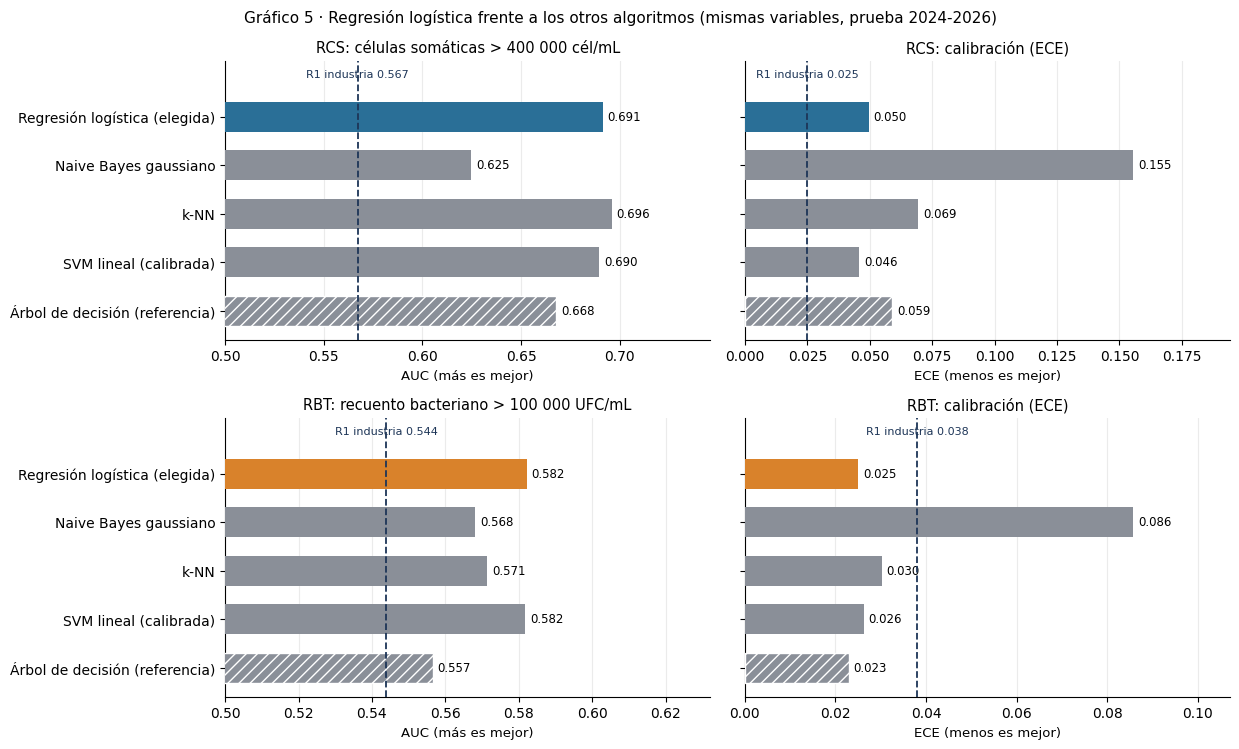

In [25]:
fig, ax = plt.subplots(2, 2, figsize=(12.5, 7.6))
nombres_alg = list(ALG.values())
for i, t in enumerate(L.OBJETIVOS):
    s = CMP[CMP["objetivo"] == t].set_index("algoritmo")
    r1 = s.loc["R1 industria (referencia)"]
    for j, (col, lab) in enumerate([("AUC", "AUC (más es mejor)"), ("ECE", "ECE (menos es mejor)")]):
        a = ax[i, j]
        v = s.loc[nombres_alg, col]
        ypos = np.arange(len(nombres_alg))
        colores = [COLOR[t] if n.startswith("Regresión") else GRIS for n in nombres_alg]
        barras = a.barh(ypos, v.to_numpy(), color=colores, height=0.62, zorder=3)
        for b_, n in zip(barras, nombres_alg):
            if n.startswith("Árbol"):
                b_.set_hatch("///"); b_.set_edgecolor("white")
        a.axvline(r1[col], color=OSCURO, ls="--", lw=1.3, zorder=4)
        lo_x, hi_x = (0.5, max(v.max(), r1[col]) + 0.05) if col == "AUC" else (0, max(v.max(), r1[col]) * 1.25)
        a.set_xlim(lo_x, hi_x)
        for yy, val_ in zip(ypos, v.to_numpy()):
            a.text(val_ + (hi_x - lo_x) * 0.01, yy, f"{val_:.3f}", va="center", fontsize=8.5)
        a.text(r1[col], -0.78, f"R1 industria {r1[col]:.3f}", ha="center", va="bottom", fontsize=8, color=OSCURO)
        a.set_yticks(ypos); a.set_yticklabels(nombres_alg if j == 0 else [""] * len(ypos)); a.invert_yaxis()
        a.set_ylim(len(nombres_alg) - 0.4, -1.15)
        a.set_xlabel(lab); a.set_title(f"{t}: {NOMBRE[t]}" if j == 0 else f"{t}: calibración (ECE)")
        a.grid(axis="y", visible=False)
fig.suptitle("Gráfico 5 · Regresión logística frente a los otros algoritmos (mismas variables, prueba 2024-2026)", fontsize=11)
fig.tight_layout()
guardar(fig, "05_comparacion_algoritmos.png")

In [26]:
def fmt(x, n=3):
    return f"{x:.{n}f}".replace(".", ",")

PARES = lambda s: s.drop(index="R1 industria (referencia)")
lineas = ["**Veredicto de la comparación (prueba 2024-2026; las diferencias de AUC menores a 0,005 se tratan como empate: es un criterio de este cuaderno, no un test).**", ""]
for t in L.OBJETIVOS:
    s = PARES(CMP[CMP["objetivo"] == t].set_index("algoritmo"))
    lg = s.loc["Regresión logística (elegida)"]
    mejor_auc, mejor_ll, mejor_ece = s["AUC"].idxmax(), s["log-loss"].idxmin(), s["ECE"].idxmin()
    emp = [n for n in s.index if n != "Regresión logística (elegida)" and abs(s.loc[n, "AUC"] - lg["AUC"]) < 0.005]
    ref_ar = s.loc["Árbol de decisión (referencia)"]
    lineas.append(f"**{t}.** AUC más alto: **{mejor_auc}** ({fmt(s.loc[mejor_auc, 'AUC'])}); la logística tiene {fmt(lg['AUC'])} ({'gana' if mejor_auc.startswith('Regresión') else 'diferencia de ' + fmt(s.loc[mejor_auc, 'AUC'] - lg['AUC'])}). "
                  f"Empatan con ella (menos de 0,005): {', '.join(emp) if emp else 'ninguno'}. Menor log-loss: **{mejor_ll}** ({fmt(s.loc[mejor_ll, 'log-loss'], 4)} contra {fmt(lg['log-loss'], 4)} de la logística). "
                  f"Mejor calibración (ECE): **{mejor_ece}** ({fmt(s.loc[mejor_ece, 'ECE'])} contra {fmt(lg['ECE'])}).")
    lineas.append(f"* Una industria afuera (sin industria en el modelo): AUC ponderado " + ", ".join(f"{n.split(' (')[0]} {fmt(s.loc[n, 'AUC industria afuera'])}" for n in s.index) +
                  f"; sesgo medio absoluto " + ", ".join(f"{n.split(' (')[0]} {fmt(s.loc[n, '|sesgo| industria afuera'])}" for n in s.index) + ".")
    lineas.append(f"* Tiempo de ajuste: " + ", ".join(f"{n.split(' (')[0]} {s.loc[n, 'tiempo de ajuste (s)']:.1f} s".replace('.', ',') for n in s.index) + f"; predecir la prueba con el k-NN (k = {HP_CMP[(t, 'knn')]}) tardó {s.loc['k-NN', 'tiempo de predicción (s)']:.0f} s. El árbol de referencia (profundidad {HP_CMP[(t, 'arbol')]}): AUC {fmt(ref_ar['AUC'])}, ECE {fmt(ref_ar['ECE'])}.")
    lineas.append("")
display(Markdown("\n".join(lineas)))

**Veredicto de la comparación (prueba 2024-2026; las diferencias de AUC menores a 0,005 se tratan como empate: es un criterio de este cuaderno, no un test).**

**RCS.** AUC más alto: **k-NN** (0,696); la logística tiene 0,691 (diferencia de 0,004). Empatan con ella (menos de 0,005): k-NN, SVM lineal (calibrada). Menor log-loss: **Regresión logística (elegida)** (0,6402 contra 0,6402 de la logística). Mejor calibración (ECE): **SVM lineal (calibrada)** (0,046 contra 0,050).
* Una industria afuera (sin industria en el modelo): AUC ponderado Regresión logística 0,645, Naive Bayes gaussiano 0,646, k-NN 0,649, SVM lineal 0,645, Árbol de decisión 0,641; sesgo medio absoluto Regresión logística 0,063, Naive Bayes gaussiano 0,063, k-NN 0,062, SVM lineal 0,063, Árbol de decisión 0,062.
* Tiempo de ajuste: Regresión logística 0,2 s, Naive Bayes gaussiano 0,1 s, k-NN 0,1 s, SVM lineal 0,8 s, Árbol de decisión 0,2 s; predecir la prueba con el k-NN (k = 3000) tardó 43 s. El árbol de referencia (profundidad 3): AUC 0,668, ECE 0,059.

**RBT.** AUC más alto: **Regresión logística (elegida)** (0,582); la logística tiene 0,582 (gana). Empatan con ella (menos de 0,005): SVM lineal (calibrada). Menor log-loss: **SVM lineal (calibrada)** (0,5092 contra 0,5101 de la logística). Mejor calibración (ECE): **Árbol de decisión (referencia)** (0,023 contra 0,025).
* Una industria afuera (sin industria en el modelo): AUC ponderado Regresión logística 0,553, Naive Bayes gaussiano 0,552, k-NN 0,558, SVM lineal 0,553, Árbol de decisión 0,548; sesgo medio absoluto Regresión logística 0,042, Naive Bayes gaussiano 0,042, k-NN 0,041, SVM lineal 0,042, Árbol de decisión 0,042.
* Tiempo de ajuste: Regresión logística 0,4 s, Naive Bayes gaussiano 0,1 s, k-NN 0,1 s, SVM lineal 0,4 s, Árbol de decisión 0,1 s; predecir la prueba con el k-NN (k = 3000) tardó 42 s. El árbol de referencia (profundidad 2): AUC 0,557, ECE 0,023.


**Por qué la regresión logística, a la vista de los números de arriba.** (Lo que sigue se lee junto con la tabla y el veredicto generado; si se vuelve a ejecutar con otros datos, hay que revisar estas frases.)
* **No gana en todo, y no hace falta.** En RCS el k-NN le saca 0,004 de AUC, pero queda peor en log-loss (0,6421 contra 0,6402) y en ECE (0,069 contra 0,050); en RBT la logística tiene el AUC más alto, y el SVM lineal la supera por 0,0009 de log-loss. Entre la logística, el SVM lineal y el k-NN
  las diferencias de AUC son de 0,011 o menos en los dos objetivos (el SVM lineal empata con la logística en los dos; el k-NN, solo en RCS: en RBT queda 0,011 por debajo), mucho menos que lo que separa a cualquiera de ellos de la referencia por industria R1 (0,12 en RCS y 0,04 en RBT). Con solo estas variables (estación, anomalía e industria) el techo de discriminación es bajo para todos:
  la información que hay es poca, no el algoritmo. Un modelo más flexible (k-NN, árbol) no encuentra estructura nueva que la logística no vea. El SVM lineal es, en la práctica, el mismo modelo (frontera lineal) con otra pérdida.
* **Calibración.** El entregable es una probabilidad. Naive Bayes es el único claramente peor: su log-loss (0,80 en RCS y 0,74 en RBT) es peor que el de predecir la tasa global, y su ECE es 3 a 4 veces mayor, porque supone variables independientes y gaussianas
  (la estación `sen`/`cos` y la industria en one-hot no lo son) y sus probabilidades salen demasiado extremas. El k-NN tiene el ECE peor que la logística en los dos objetivos; el SVM lineal necesita la corrección de Platt encima para dar una probabilidad y queda a la par
  (algo mejor en RCS, algo peor en RBT); el árbol de referencia tiene el menor ECE en RBT, pero con profundidad 2 es un modelo muy simple y su AUC es de los más bajos (0,668 en RCS y 0,557 en RBT).
* **Interpretabilidad.** La pregunta del trabajo es si el calor sube el riesgo. Solo la regresión logística da un **odds ratio por °C de anomalía con intervalo** (sección 8), con la estación y la industria descontadas. Con k-NN, Naive Bayes o un árbol habría que armar gráficos de dependencia parcial y
  no se tendría un intervalo; los coeficientes del SVM lineal están en la escala del margen y no son odds. Por esto la logística responde la pregunta del trabajo y los demás no, aunque el k-NN discrimine un poco más en RCS.
* **Estabilidad dejando una industria afuera.** Sin el nivel propio de la industria el rendimiento de todos baja a AUC 0,64-0,65 (RCS) y 0,55-0,56 (RBT), y las diferencias entre algoritmos se mantienen chicas (k-NN apenas arriba: 0,649 y 0,558; Naive Bayes queda a la par de la logística, probablemente porque sin la industria en one-hot su supuesto de independencia pesa menos). El sesgo medio absoluto es casi el mismo para todos (0,062-0,063 en RCS y 0,041-0,042 en RBT): ningún algoritmo, por flexible que sea, aprende el nivel de una industria que no vio (sección 10).
* **Costo.** La logística se ajusta en una fracción de segundo con todas las filas. El k-NN hay que submuestrearlo (50 000 filas) porque la predicción compara cada fila contra el entrenamiento: tarda unos 40 s en predecir la prueba (el tiempo exacto cambia de una corrida a otra), contra décimas de segundo de la logística. Además, en los dos objetivos el `k` elegido (3000) es el
  extremo de la grilla: un `k` mayor podría mejorar un poco más (hacia un modelo casi constante), lo que dice que ahí el k-NN no encuentra estructura local.
* **Qué quedó afuera.** SVM con núcleo (RBF) y k-NN con todo el entrenamiento: con 300 000 filas son caros, y el SVM lineal y el k-NN submuestreado ya muestran que los modelos más flexibles no separan mejor. El árbol de decisión lo trabaja otro integrante del grupo: acá es solo un punto de comparación.

## 14 · Datos usados en cada entrenamiento
Cuántas filas de la leche cruda entran en cada modelo de este cuaderno, cuáles se sacan y por qué, y cómo se reparten entre entrenamiento, validación y prueba. La validación sale del propio pasado:
C y la ventana de temperatura se eligen con la validación móvil 2021-2023 (cada año se valida con un modelo ajustado con los años anteriores) y los hiperparámetros de la sección 13, entrenando hasta 2022 y validando en 2023;
el modelo final se reajusta siempre con todo hasta 2023. Por eso «entrenamiento» cuenta las filas anteriores al período de validación y «validación» las de ese período (las dos juntas ajustan el modelo final). La prueba es 2024-2026 y no decide nada.
Las submuestras del k-NN figuran en la nota.

In [27]:
import inspect
import datos_entrenamiento as DE

mil = lambda n: f"{int(n):,}".replace(",", ".")
N_ARCHIVO = int(info["filas_archivo"])
ANTES_INICIO = N_ARCHIVO - len(d)
ANIOS_VAL = inspect.signature(L.validar_rodante).parameters["anios"].default        # 2021-2023, la validación móvil de la sección 6
INI_VAL = pd.Timestamp(ANIOS_VAL[0], 1, 1)
UBI = L.CAMBIO_UNIDAD_RBT["cliente"]


def motivo(t):
    y = L.OBJETIVOS[t]
    p = []
    if ANTES_INICIO:
        p.append(f"anteriores a {L.INICIO.year}: {mil(ANTES_INICIO)}")
    if t == "RCS":
        p.append(f"sin valor de células somáticas: {mil(d['celulas_somaticas'].isna().sum() - info['rcs_descartados_ind59'])}")
        p.append(f"RCS redondos de {UBI} desde junio de 2024 (parecen un RBT mal ubicado): {mil(info['rcs_descartados_ind59'])}")
    else:
        p.append(f"sin valor de RBT: {mil(d['rbt'].isna().sum())}")
        p.append(f"RBT de {UBI} desde mayo de 2024 (UFC/mL con tope de 100.000, no se sabe si pasó el umbral): {mil((d['rbt'].notna() & d['rbt_corr'].isna()).sum())}")
    p.append(f"sin temperatura de la ventana ({ELEG[t][0]} de {ELEG[t][1]} días): {mil(d[y].notna().sum() - len(DATOS[t]))}")
    return "; ".join(p)


def reparto(x, ini_val):
    f = x["fecha"]
    return int((f < ini_val).sum()), int(((f >= ini_val) & (f < L.CORTE_PRUEBA)).sum()), int((f >= L.CORTE_PRUEBA).sum())


filas = []
PART_M = "temporal: hasta 2023 / prueba 2024-26; C y ventana con validación móvil 2021-23"
PART_A = "temporal: hasta 2022 / validación 2023 / prueba 2024-26"
for t in L.OBJETIVOS:
    x, y = DATOS[t], L.OBJETIVOS[t]
    m = motivo(t)
    n_sacadas = ANTES_INICIO + int(d[y].isna().sum()) + int(d[y].notna().sum() - len(x))
    assert N_ARCHIVO - n_sacadas == len(x), (N_ARCHIVO, n_sacadas, len(x))
    n_pre, n_val, n_pru = reparto(x, INI_VAL)
    n_h23 = n_pre + n_val
    filas.append(DE.fila("IV", f"logística M3 (estación + anomalía + industria), {t}", f"muestras de leche cruda con {t} y temperatura", N_ARCHIVO, len(x), m,
                         entrenamiento=n_pre, validacion=n_val, prueba=n_pru, particion=PART_M, nota=f"C = {C_ELEG[t]:g}; el modelo final se reajusta con todo hasta 2023 ({mil(n_h23)} filas)"))
    xs = SUB[t]
    s_pre, s_val, s_pru = reparto(xs, INI_VAL)
    filas.append(DE.fila("IV", f"logística C2 (M3 + lactosa, grasa y proteína), {t}", "muestras con la composición completa", N_ARCHIVO, len(xs), m + f"; sin lactosa, grasa o proteína: {mil(len(x) - len(xs))}",
                         entrenamiento=s_pre + s_val, prueba=s_pru, particion="temporal: hasta 2023 / prueba 2024-26", nota=f"mismo C que M3 ({C_ELEG[t]:g}); sin validación propia"))
    filas.append(DE.fila("IV", f"logística de interpretación (OR por +1 °C con mes e industria), {t}", f"muestras de leche cruda con {t} y temperatura", N_ARCHIVO, len(x), m,
                         particion="sin partición: todos los datos 2019-2026, intervalos por bootstrap de semanas", nota=f"celdas industria × día: {mil(OR[t]['celdas'])}; 300 remuestreos"))
    g = LOIO[t]
    filas.append(DE.fila("IV", f"industria afuera: logística S2 (estación + anomalía) y S3 (+ composición), {t}", f"muestras de leche cruda con {t} y temperatura", N_ARCHIVO, len(x), m,
                         entrenamiento=len(x) - int(round(g["filas"].mean())), prueba=int(round(g["filas"].mean())), particion=f"una industria afuera por vez ({len(g)} industrias)",
                         nota="entrenamiento y prueba son el promedio por industria dejada afuera; sin término de industria; S3 usa solo las filas con composición"))
    e22, v23, p24 = reparto(x, L.CORTE_VALID)
    HP = {c: HP_CMP[(t, c)] for c in ALG}
    NOTA = {
        "nb": "sin hiperparámetros; sin submuestra",
        "knn": f"SUBMUESTRA: entrena con {mil(min(N_KNN, e22))} filas al azar de las {mil(e22)} hasta 2022 al elegir k y con {mil(min(N_KNN, e22 + v23))} al azar de las {mil(e22 + v23)} hasta 2023 en el ajuste final; "
               f"elige k con {mil(min(N_VAL_KNN, v23))} filas al azar de 2023; k = {HP['knn']}",
        "svm": f"C = {HP['svm']:g} elegido por validación; Platt con 3 pliegues al azar dentro del entrenamiento; sin submuestra",
        "arbol": f"profundidad {HP['arbol']} elegida por validación; hojas de al menos 200 filas; sin submuestra"}
    for c in ("nb", "knn", "svm", "arbol"):
        filas.append(DE.fila("IV", f"sección 13: {ALG[c]}, {t}", f"muestras de leche cruda con {t} y temperatura", N_ARCHIVO, len(x), m,
                             entrenamiento=e22, validacion=v23, prueba=p24, particion=PART_A, nota=NOTA[c] + f"; el modelo final se reajusta con todo hasta 2023 ({mil(e22 + v23)} filas)"))
    dd = det[det["objetivo"] == t]
    n_ind = dd["industria"].nunique()
    f_prom = int(round(dd[dd["algoritmo"] == ALG["log"]]["filas"].mean()))
    filas.append(DE.fila("IV", f"industria afuera: los cinco algoritmos de la sección 13, {t}", f"muestras de leche cruda con {t} y temperatura", N_ARCHIVO, len(x), m,
                         entrenamiento=len(x) - f_prom, prueba=f_prom, particion=f"una industria afuera por vez ({n_ind} industrias)",
                         nota=f"entrenamiento y prueba son el promedio por industria dejada afuera; sin término de industria; el k-NN entrena con {mil(N_KNN)} filas al azar en cada pliegue (SUBMUESTRA)"))
display(DE.guardar(filas, "logistica_calidad_leche_cruda"))

,parte,modelo,datos,disponibles,excluidas,motivo de exclusión,usadas,entrenamiento,validación,prueba,partición,nota
0,IV,logística M3 (estación + anomalía + industria)...,muestras de leche cruda con RCS y temperatura,628035,157986,anteriores a 2019: 33; sin valor de células so...,470049,74776,220585,174688,temporal: hasta 2023 / prueba 2024-26; C y ven...,C = 0.001; el modelo final se reajusta con tod...
1,IV,"logística C2 (M3 + lactosa, grasa y proteína),...",muestras con la composición completa,628035,238610,anteriores a 2019: 33; sin valor de células so...,389425,240839,<NA>,148586,temporal: hasta 2023 / prueba 2024-26,mismo C que M3 (0.001); sin validación propia
2,IV,logística de interpretación (OR por +1 °C con ...,muestras de leche cruda con RCS y temperatura,628035,157986,anteriores a 2019: 33; sin valor de células so...,470049,470049,<NA>,<NA>,"sin partición: todos los datos 2019-2026, inte...",celdas industria × día: 7.305; 300 remuestreos
3,IV,industria afuera: logística S2 (estación + ano...,muestras de leche cruda con RCS y temperatura,628035,157986,anteriores a 2019: 33; sin valor de células so...,470049,423044,<NA>,47005,una industria afuera por vez (10 industrias),entrenamiento y prueba son el promedio por ind...
4,IV,"sección 13: Naive Bayes gaussiano, RCS",muestras de leche cruda con RCS y temperatura,628035,157986,anteriores a 2019: 33; sin valor de células so...,470049,212889,82472,174688,temporal: hasta 2022 / validación 2023 / prueb...,sin hiperparámetros; sin submuestra; el modelo...
5,IV,"sección 13: k-NN, RCS",muestras de leche cruda con RCS y temperatura,628035,157986,anteriores a 2019: 33; sin valor de células so...,470049,212889,82472,174688,temporal: hasta 2022 / validación 2023 / prueb...,SUBMUESTRA: entrena con 50.000 filas al azar d...
6,IV,"sección 13: SVM lineal (calibrada), RCS",muestras de leche cruda con RCS y temperatura,628035,157986,anteriores a 2019: 33; sin valor de células so...,470049,212889,82472,174688,temporal: hasta 2022 / validación 2023 / prueb...,C = 0.1 elegido por validación; Platt con 3 pl...
7,IV,"sección 13: Árbol de decisión (referencia), RCS",muestras de leche cruda con RCS y temperatura,628035,157986,anteriores a 2019: 33; sin valor de células so...,470049,212889,82472,174688,temporal: hasta 2022 / validación 2023 / prueb...,profundidad 3 elegida por validación; hojas de...
8,IV,industria afuera: los cinco algoritmos de la s...,muestras de leche cruda con RCS y temperatura,628035,157986,anteriores a 2019: 33; sin valor de células so...,470049,423044,<NA>,47005,una industria afuera por vez (10 industrias),entrenamiento y prueba son el promedio por ind...
9,IV,logística M3 (estación + anomalía + industria)...,muestras de leche cruda con RBT y temperatura,628035,112283,anteriores a 2019: 33; sin valor de RBT: 91.03...,515752,107247,233257,175248,temporal: hasta 2023 / prueba 2024-26; C y ven...,C = 0.001; el modelo final se reajusta con tod...


In [28]:
print(f"Notebook completo en {time.time() - T0:.0f} s. Archivos en {SALIDA}:")
for p in sorted(SALIDA.iterdir()):
    print(" ", p.name)

Notebook completo en 590 s. Archivos en E:\Downloads\UNRaf\4to cuatrimestre\IA\trabajo_senasa_mq\resultados\logistica_calidad_leche:
  01_tasa_positivos_mes_temperatura.png
  02_roc_calibracion.png
  03_odds_ratio.png
  04_probabilidad_vs_lactosa.png
  05_comparacion_algoritmos.png
  comparacion_algoritmos.csv
  comparacion_algoritmos_industria_afuera.csv
  compromiso_umbrales.csv
  industria_afuera_rbt.csv
  industria_afuera_rcs.csv
  matriz_confusion_umbral_youden.csv
  metricas_prueba_con_composicion.csv
  metricas_prueba_modelos_anidados.csv
  odds_ratio_composicion_rbt.csv
  odds_ratio_composicion_rcs.csv
  odds_ratio_rbt.csv
  odds_ratio_rcs.csv
  or_calor_robustez.csv
  or_temperatura_segun_control.csv
  regularizacion_y_balanceo.csv
  seleccion_ventana_temperatura.csv
  sensibilidad_umbral.csv
  tasa_positivos_industria_anio_rbt.csv
  tasa_positivos_industria_anio_rcs.csv
